# Dialect-aware Hindi TTS · MTP toolkit (Google Colab)

Your notebook (sections 1–6, with your `torch.load` fix kept) **plus** the MTP workflow built on the
*MTP Hindi Dialect TTS Dataset*:

| Section | MTP-1 methodology | Objective |
|---|---|---|
| 2b Load dataset | 4.1 Data collection and dataset development | 2 |
| 3 Dialect transform | 4.2 Feature extraction (phonetic, lexical) | 3 |
| 4 Engines | 4.3 Neural TTS (Indic-TTS, Indic Parler-TTS) | 1, 4 |
| 7 Generate the 100 stimuli (20 sentences × 5 models) | 4.1 / 4.3 / 4.4 SSML | 1, 3 |
| 8 Natural references | 4.1 | 2 |
| 9 Feature extraction (prosody) | 4.2 prosodic level | 3 |
| 10 Ratings + bias correction y = ax + b | 4.5 | 5, 6 |

**Before you start:** `Runtime → Change runtime type → T4 GPU`. Upload `MTP_Hindi_Dialect_Dataset.zip`
when section 2b asks for it (or put it in Google Drive and set `DATASET_ZIP`).
Set `USE_PARLER = True` in section 1 to build M2 and M5 (needs about 4 GB download and a GPU).

In [1]:
# @title 1 · Settings { display-mode: "form" }
ENGINE  = "indic_tts"   # @param ["indic_tts", "indic_parler", "gtts"]
SPEAKER = "male"      # @param ["female", "male"]
DIALECT = "bihari"    # @param ["haryanvi", "chhattisgarhi", "bundeli", "brajbhasha", "awadhi", "bihari", "khadiboli"]
MODE    = "combined"    # @param ["combined", "lexicon", "char", "standard"]
LEVEL   = "conservative"  # @param ["conservative", "full"]
TEXT    = "किसी एक गाँव में एक कुत्ता रहता था। वह पूरे दिन भोजन की तलाश में यहाँ-वहां भटकता रहता था। एक दिन उसे कहीं से मांस का एक टुकड़ा मिल गया। वह बहुत खुश हुआ। वह उस टुकड़े को अपने मुँह में दबाकर, सुरक्षित बैठकर खाने के लिए एक सुनसान जगह की ओर भागने लगा।"  # @param {type:"string"}

USE_INDIC  = True    # @param {type:"boolean"}
USE_PARLER = False   # @param {type:"boolean"}
DATASET_ZIP = "/content/MTP_Hindi_Dialect_Dataset.zip"  # @param {type:"string"}

import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("engine:", ENGINE, "| device:", DEVICE)

engine: indic_tts | device: cuda


## 2 · Dialect module and MTP toolkit modules
These cells write the code to `/content/hindi_dialect`. No changes needed.

In [2]:
import os
for d in ["app/dialects", "app/features", "app/evaluation", "app/data", "app/synthesis", "app/utils", "data/lexicon"]:
    os.makedirs(f"/content/hindi_dialect/{d}", exist_ok=True)
for d in ["app", "app/features", "app/evaluation", "app/data", "app/synthesis", "app/utils"]:
    open(f"/content/hindi_dialect/{d}/__init__.py", "a").close()

In [3]:
%%writefile /content/hindi_dialect/app/dialects/devanagari.py
"""Devanagari helpers shared by the dialect rules.

All text is normalised to Unicode NFC before rules run. Note that NFC
*decomposes* the precomposed nukta letters (U+0958..U+095F), so ड़ is always
the two code points "ड" + "़" (U+0921 U+093C) after normalisation.
"""
from __future__ import annotations

import re
import unicodedata

NUKTA = "़"
VIRAMA = "्"
CHANDRABINDU = "ँ"
ANUSVARA = "ं"

RRA = "ड" + NUKTA    # ड़
RHA = "ढ" + NUKTA    # ढ़

# A consonant, optionally followed by a nukta.
CONSONANT = r"[क-ह]" + NUKTA + "?"
# Dependent vowel signs (matras) ा ि ी ु ू ृ ॄ ॅ ॆ े ै ॉ ॊ ो ौ
MATRA = r"[ा-ौ]"
LONG_MATRA = "[ाीूेैोौ]"   # ा ी ू े ै ो ौ
LONG_INDEPENDENT_VOWEL = "[आईऊएऐओऔ]"  # आ ई ऊ ए ऐ ओ औ

# A "word" is a run of Devanagari letters/marks. Danda (।) and double danda
# (॥) are excluded so punctuation survives untouched.
WORD_RE = re.compile(r"[ऀ-ॣ०-ॿ]+")

# Aspirated (महाप्राण) -> unaspirated (अल्पप्राण) partner, used for gemination:
# देखा -> देक्खा, भूखा -> भुक्खा (the geminate is written unaspirated + virama + aspirated).
ASPIRATE_TO_PLAIN = {
    "ख": "क", "घ": "ग", "छ": "च", "झ": "ज", "ठ": "ट",
    "ढ": "ड", "थ": "त", "ध": "द", "फ": "प", "भ": "ब",
}


def nfc(text: str) -> str:
    return unicodedata.normalize("NFC", text)


def geminate(consonant: str) -> str:
    """Return the doubled (geminated) written form of a consonant.

    >>> geminate("ज")
    'ज्ज'
    >>> geminate("ख")
    'क्ख'
    """
    if consonant.endswith(NUKTA):          # ड़ -> ड्ड (paper: गाड़ी -> गाड्डी)
        base = consonant[0]
        return base + VIRAMA + base
    plain = ASPIRATE_TO_PLAIN.get(consonant, consonant)
    return plain + VIRAMA + consonant

Writing /content/hindi_dialect/app/dialects/devanagari.py


In [4]:
%%writefile /content/hindi_dialect/app/dialects/rules.py
"""Character-level dialect rules (paper Table 4: "Dialect Characters Variations").

Each rule rewrites a *single Hindi word* (rules never cross word boundaries)
into the spelling that makes a Hindi TTS front-end pronounce it the way a
speaker of the target dialect would. Rules have a ``level``:

* ``conservative`` – regular, high-precision sound correspondences
  (e.g. Haryanvi श→स, word-final थ→त; Awadhi ण→न).
* ``full`` – every pattern reported in the paper, including ones that only
  hold for part of the vocabulary (e.g. Chhattisgarhi word-initial स→छ).
  Use for experiments; prefer the lexicon for production.

Rules are deliberately data, not code paths, so a linguist can review
``RULES`` without reading the transformer.
"""
from __future__ import annotations

import re
from dataclasses import dataclass, field
from typing import Callable, Literal

from .devanagari import (
    ANUSVARA,
    CHANDRABINDU,
    LONG_INDEPENDENT_VOWEL,
    LONG_MATRA,
    MATRA,
    NUKTA,
    RRA,
    VIRAMA,
    geminate,
)

Level = Literal["conservative", "full"]
LEVEL_ORDER = {"conservative": 0, "full": 1}


@dataclass(frozen=True)
class Dialect:
    code: str
    name: str
    hindi_name: str
    region: str
    is_reference: bool = False


DIALECTS: dict[str, Dialect] = {
    d.code: d
    for d in [
        Dialect("khadiboli", "Khadi Boli", "खड़ी बोली", "Western UP, Delhi (reference dialect)", True),
        Dialect("haryanvi", "Haryanvi", "हरियाणवी", "Haryana, Delhi"),
        Dialect("chhattisgarhi", "Chhattisgarhi", "छत्तीसगढ़ी", "Chhattisgarh and adjacent areas"),
        Dialect("awadhi", "Awadhi", "अवधी", "Central/Eastern Uttar Pradesh"),
        Dialect("brajbhasha", "Braj Bhasha", "ब्रजभाषा", "Mathura-Agra region, UP"),
        Dialect("bihari", "Bihari", "बिहारी", "Bihar"),
        Dialect("bundeli", "Bundeli / Bundelkhandi", "बुंदेली", "Bundelkhand (MP and southern UP)"),
    ]
}
REFERENCE_DIALECT = "khadiboli"


@dataclass(frozen=True)
class Rule:
    id: str
    dialect: str
    pattern: str
    repl: str | Callable[[re.Match], str]
    description: str
    level: Level = "conservative"
    examples: tuple[tuple[str, str], ...] = field(default_factory=tuple)

    def compiled(self) -> re.Pattern:
        return _compile(self.pattern)

    def apply(self, word: str) -> str:
        return self.compiled().sub(self.repl, word)


_CACHE: dict[str, re.Pattern] = {}


def _compile(pattern: str) -> re.Pattern:
    if pattern not in _CACHE:
        _CACHE[pattern] = re.compile(pattern)
    return _CACHE[pattern]


# --------------------------------------------------------------------------
# Gemination ("single consonant is replaced by dual consonant")
# राजा→राज्जा, चाचा→चाच्चा, आलू→आल्लू, ढीला→ढील्ला, हँसी→हँस्सी, गाड़ी→गाड्डी,
# देखा→देक्खा (aspirate geminates as unaspirated + virama + aspirate).
# Context: after a long vowel (or a nasalised vowel), before a word-final vowel.
# --------------------------------------------------------------------------
def _gemination_pattern(excluded: str, short_initial: bool = False) -> str:
    alts = [LONG_MATRA, f"^{LONG_INDEPENDENT_VOWEL}", f"[{CHANDRABINDU}{ANUSVARA}]"]
    if short_initial:   # Khadi Boli also doubles after a short first syllable: बड़ा→बड्डा
        alts.append(r"^[\u0915-\u0939]")
    left = "(?:" + "|".join(alts) + ")"
    cons = rf"(?![{excluded}])[क-ह]{NUKTA}?"
    final_vowel = "[ाीूेो]$"      # ा ी ू े ो
    return rf"(?P<left>{left})(?P<c>{cons})(?={final_vowel})"


def _geminate_repl(m: re.Match) -> str:
    c = m.group("c")
    if c.endswith(NUKTA) and c[0] != "ड":     # only ड़ geminates among nukta letters
        return m.group(0)
    return m.group("left") + geminate(c)


# Haryanvi changes न→ण separately, so nasals are not geminated there.
_HAR_GEM = _gemination_pattern("नणमयरहवशष")
_KHADI_GEM = _gemination_pattern("णयरहवशष", short_initial=True)


RULES: list[Rule] = [
    # ---------------------------------------------------------------- Haryanvi
    Rule("har_sha_sa", "haryanvi", "[शष]", "स", "श/ष are pronounced स", "conservative",
         (("आकाश", "आकास"),)),
    Rule("har_tha_ta_final", "haryanvi", "थ$", "त", "word-final थ → त", "conservative",
         (("हाथ", "हात"), ("साथ", "सात"))),
    Rule("har_na_nna", "haryanvi", rf"(?<=[ऀ-ॿ])(?<!{VIRAMA})न(?!{VIRAMA})", "ण",
         "non-initial न → ण (retroflex nasal)", "conservative",
         (("अपने", "अपणे"), ("खाना", "खाणा"), ("चना", "चणा"))),
    Rule("har_rra_ra", "haryanvi", RRA, "र", "ड़ → र", "full", (("कीड़ी", "कीरी"),)),
    Rule("har_la_ra", "haryanvi", "(?<=ा)ल(?=ा$)", "र", "intervocalic ल → र (आ_आ)", "full",
         (("काला", "कारा"),)),
    Rule("har_gemination", "haryanvi", _HAR_GEM, _geminate_repl,
         "consonant after a long vowel is doubled", "full",
         (("राजा", "राज्जा"), ("चाचा", "चाच्चा"), ("आलू", "आल्लू"), ("ढीला", "ढील्ला"),
          ("हँसी", "हँस्सी"), ("आँसू", "आँस्सू"), ("ऊँचा", "ऊँच्चा"), ("गाड़ी", "गाड्डी"))),

    # ----------------------------------------------------------- Chhattisgarhi
    Rule("chh_chah_chhe", "chhattisgarhi", "चह", "छे", "चह → छे", "conservative",
         (("कचहरी", "कछेरी"),)),
    Rule("chh_aa_e_ye", "chhattisgarhi", "(?<=[ाआ])ए", "ये", "ए after आ/ा → ये", "conservative",
         (("आए", "आये"),)),
    Rule("chh_ja_jha", "chhattisgarhi", rf"^ज(?![{NUKTA}{VIRAMA}])", "झ", "initial ज → झ", "full",
         (("जन", "झन"),)),
    Rule("chh_da_dha", "chhattisgarhi", rf"^द(?![{NUKTA}{VIRAMA}])", "ध", "initial द → ध", "full",
         (("दौड़", "धौड़"),)),
    Rule("chh_ka_kha", "chhattisgarhi", rf"(?<={MATRA})क(?={MATRA}$)", "ख",
         "intervocalic final-syllable क → ख", "full", (("इलाका", "इलाखा"),)),
    Rule("chh_sa_chha", "chhattisgarhi", rf"^स(?!{VIRAMA})", "छ", "initial स → छ", "full",
         (("सीता", "छीता"),)),
    Rule("chh_ba_pa_final", "chhattisgarhi", "ब$", "प", "word-final ब → प", "full",
         (("शराब", "शराप"), ("खराब", "खराप"))),
    Rule("chh_ma_va_final", "chhattisgarhi", "(?<=ा)म$", "व", "word-final म after आ → व", "full",
         (("नाम", "नाव"),)),
    Rule("chh_ga_ka", "chhattisgarhi", "(?<=[क-ह])ग(?=ी$)", "क", "ग → क before final ी", "full",
         (("बंदगी", "बंदकी"),)),

    # ------------------------------------------------------------------ Awadhi
    Rule("awa_nna_na", "awadhi", "ण", "न", "ण → न", "conservative",
         (("गुण", "गुन"), ("लक्ष्मण", "लक्ष्मन"))),
    Rule("awa_va_ba", "awadhi", "^व", "ब", "initial व → ब", "conservative",
         (("वाहन", "बाहन"), ("वन", "बन"), ("व्याकुल", "ब्याकुल"))),
    Rule("awa_sha_sa", "awadhi", "[शष]", "स", "श/ष → स", "conservative",
         (("शंकर", "संकर"), ("शाम", "साम"), ("शेर", "सेर"))),
    Rule("awa_ri", "awadhi", "ऋ", "रि", "ऋ → रि", "conservative", (("ऋतु", "रितु"),)),
    Rule("awa_ri_matra", "awadhi", "ृ", VIRAMA + "रि", "vowel sign ृ → ्रि", "full",
         (("कृपा", "क्रिपा"),)),
    Rule("awa_prothetic_i", "awadhi", rf"^स{VIRAMA}(?=[कटतपथमन])", "इस" + VIRAMA,
         "prothetic इ before initial स-cluster", "conservative",
         (("स्कूल", "इस्कूल"), ("स्त्री", "इस्त्री"))),
    Rule("awa_rra_ra", "awadhi", RRA, "र", "ड़ → र", "full", (("किवाड़", "किवार"),)),
    Rule("awa_da_dda", "awadhi", rf"^द(?![{NUKTA}{VIRAMA}])", "ड", "initial द → ड", "full",
         (("दंड", "डंड"),)),

    # ------------------------------------------------------------- Braj Bhasha
    Rule("bra_rra_ra", "brajbhasha", RRA, "र", "ड़ → र", "conservative",
         (("पड़े", "परे"), ("सड़क", "सरक"))),
    Rule("bra_on_un", "brajbhasha", "ों", "ूँ", "ों → ूँ", "conservative",
         (("क्यों", "क्यूँ"), ("गोंद", "गूँद"))),
    Rule("bra_la_ra", "brajbhasha", rf"(?<=[ऀ-ॿ])(?<!{VIRAMA})ल(?!{VIRAMA})", "र",
         "non-initial ल → र", "full", (("काला", "कारा"), ("तले", "तरे"), ("बल", "बर"))),

    # ------------------------------------------------------------------ Bihari
    Rule("bih_rra_ra", "bihari", RRA, "र", "ड़ → र", "conservative",
         (("लड़का", "लरका"), ("कड़ी", "करी"))),

    # -------------------------------------------------------------- Khadi Boli
    Rule("khb_gemination", "khadiboli", _KHADI_GEM, _geminate_repl,
         "consonant after a long vowel is doubled (aspirates as unaspirated+aspirate)", "full",
         (("बेटा", "बेट्टा"), ("भेजा", "भेज्जा"), ("बड़ा", "बड्डा"), ("छोटा", "छोट्टा"),
          ("रानी", "रान्नी"), ("सादी", "साद्दी"), ("रोटी", "रोट्टी"), ("देखा", "देक्खा"))),
]


def rules_for(dialect: str, level: Level = "conservative") -> list[Rule]:
    """Rules of a dialect up to (and including) ``level``, in application order."""
    if dialect not in DIALECTS:
        raise KeyError(f"unknown dialect {dialect!r}; known: {sorted(DIALECTS)}")
    if level not in LEVEL_ORDER:
        raise ValueError(f"level must be one of {list(LEVEL_ORDER)}")
    cap = LEVEL_ORDER[level]
    return [r for r in RULES if r.dialect == dialect and LEVEL_ORDER[r.level] <= cap]

Writing /content/hindi_dialect/app/dialects/rules.py


In [5]:
%%writefile /content/hindi_dialect/app/dialects/lexicon.py
"""Hindi → dialect word dictionary ("word variations using dictionary").

The paper built ~1,500 Chhattisgarhi and ~2,100 Haryanvi entries. This repo
ships the Table-4 examples plus a few clearly-flagged ``community_seed``
entries; grow the CSVs (or the ``lexicon_entries`` DB table) to scale up.

CSV columns: hindi, dialect_form, pos, source, verified, notes
"""
from __future__ import annotations

import csv
from dataclasses import dataclass
from pathlib import Path
from typing import Iterable

from .devanagari import nfc
from .rules import DIALECTS

DEFAULT_LEXICON_DIR = Path(__file__).resolve().parents[2] / "data" / "lexicon"


@dataclass(frozen=True)
class LexiconEntry:
    dialect: str
    hindi: str
    dialect_form: str
    pos: str = ""
    source: str = ""
    verified: bool = False
    notes: str = ""


class Lexicon:
    def __init__(self, entries: Iterable[LexiconEntry] = ()):
        self._by_dialect: dict[str, dict[str, LexiconEntry]] = {}
        for e in entries:
            self.add(e)

    # -- construction -------------------------------------------------------
    def add(self, entry: LexiconEntry) -> None:
        if entry.dialect not in DIALECTS:
            raise KeyError(f"unknown dialect {entry.dialect!r}")
        e = LexiconEntry(
            entry.dialect, nfc(entry.hindi.strip()), nfc(entry.dialect_form.strip()),
            entry.pos, entry.source, entry.verified, entry.notes,
        )
        if not e.hindi or not e.dialect_form:
            raise ValueError(f"empty lexicon field in {entry!r}")
        self._by_dialect.setdefault(e.dialect, {})[e.hindi] = e

    @classmethod
    def from_csv(cls, path: str | Path, dialect: str | None = None) -> "Lexicon":
        lex = cls()
        lex.load_csv(path, dialect)
        return lex

    def load_csv(self, path: str | Path, dialect: str | None = None) -> None:
        path = Path(path)
        dialect = dialect or path.stem
        with path.open(encoding="utf-8", newline="") as fh:
            for row in csv.DictReader(fh):
                self.add(LexiconEntry(
                    dialect=dialect,
                    hindi=row["hindi"],
                    dialect_form=row["dialect_form"],
                    pos=row.get("pos", "") or "",
                    source=row.get("source", "") or "",
                    verified=(row.get("verified", "") or "").strip().lower() in {"yes", "true", "1"},
                    notes=row.get("notes", "") or "",
                ))

    @classmethod
    def from_dir(cls, directory: str | Path = DEFAULT_LEXICON_DIR,
                 verified_only: bool = False) -> "Lexicon":
        lex = cls()
        for csv_path in sorted(Path(directory).glob("*.csv")):
            if csv_path.stem in DIALECTS:
                lex.load_csv(csv_path)
        if verified_only:
            lex = cls(e for e in lex.entries() if e.verified)
        return lex

    # -- queries ------------------------------------------------------------
    def lookup(self, dialect: str, word: str) -> LexiconEntry | None:
        return self._by_dialect.get(dialect, {}).get(nfc(word))

    def entries(self, dialect: str | None = None) -> list[LexiconEntry]:
        if dialect:
            return list(self._by_dialect.get(dialect, {}).values())
        return [e for d in self._by_dialect.values() for e in d.values()]

    def __len__(self) -> int:
        return sum(len(d) for d in self._by_dialect.values())

    def dialects(self) -> list[str]:
        return sorted(self._by_dialect)

Writing /content/hindi_dialect/app/dialects/lexicon.py


In [6]:
%%writefile /content/hindi_dialect/app/dialects/transformer.py
"""Hindi text → dialect-aware text for synthesis.

Modes mirror the three conditions evaluated in the paper (Table 5):

* ``standard``  – unchanged Hindi ("Score: Hindi TTS system")
* ``char``      – character-level rules only ("Character variations")
* ``lexicon``   – dictionary substitution only ("Word variations using dictionary")
* ``combined``  – dictionary first, rules for out-of-vocabulary words (our extension)
"""
from __future__ import annotations

from dataclasses import dataclass, field
from typing import Literal

from .devanagari import WORD_RE, nfc
from .lexicon import Lexicon
from .rules import DIALECTS, Level, rules_for

Mode = Literal["standard", "char", "lexicon", "combined"]
MODES: tuple[str, ...] = ("standard", "char", "lexicon", "combined")


@dataclass(frozen=True)
class Change:
    start: int          # character offsets in the *original* (NFC) text
    end: int
    source: str         # original Hindi word
    target: str         # dialect spelling sent to the TTS
    origin: str         # "lexicon" or "rule:<rule_id>[+rule:<id>...]"


@dataclass
class TransformResult:
    original: str
    text: str
    dialect: str
    mode: str
    changes: list[Change] = field(default_factory=list)

    @property
    def n_changed(self) -> int:
        return len(self.changes)


class DialectTransformer:
    def __init__(self, dialect: str, lexicon: Lexicon | None = None,
                 level: Level = "conservative"):
        if dialect not in DIALECTS:
            raise KeyError(f"unknown dialect {dialect!r}; known: {sorted(DIALECTS)}")
        self.dialect = dialect
        self.lexicon = lexicon if lexicon is not None else Lexicon()
        self.level = level
        self.rules = rules_for(dialect, level)

    def transform_word(self, word: str, mode: Mode) -> tuple[str, str | None]:
        """Return (new_word, origin) – origin is None when nothing changed."""
        if mode == "standard":
            return word, None
        if mode in ("lexicon", "combined"):
            entry = self.lexicon.lookup(self.dialect, word)
            if entry is not None:
                return entry.dialect_form, "lexicon"
            if mode == "lexicon":
                return word, None
        # char rules (mode == "char", or OOV word in "combined")
        out, fired = word, []
        for rule in self.rules:
            new = rule.apply(out)
            if new != out:
                fired.append(f"rule:{rule.id}")
                out = new
        return out, ("+".join(fired) if fired else None)

    def transform(self, text: str, mode: Mode = "combined") -> TransformResult:
        if mode not in MODES:
            raise ValueError(f"mode must be one of {MODES}")
        text = nfc(text)
        pieces: list[str] = []
        changes: list[Change] = []
        cursor = 0
        for m in WORD_RE.finditer(text):
            pieces.append(text[cursor:m.start()])
            word = m.group(0)
            new, origin = self.transform_word(word, mode)
            pieces.append(new)
            if origin and new != word:
                changes.append(Change(m.start(), m.end(), word, new, origin))
            cursor = m.end()
        pieces.append(text[cursor:])
        return TransformResult(text, "".join(pieces), self.dialect, mode, changes)

Writing /content/hindi_dialect/app/dialects/transformer.py


In [7]:
%%writefile /content/hindi_dialect/app/dialects/ssml.py
"""Methodology 4.4 – SSML generation and interpretation.

* :func:`to_ssml` builds W3C SSML 1.1: changed words are wrapped in
  ``<sub alias="dialect form">hindi</sub>`` (pronunciation control), and an
  optional ``<prosody rate pitch volume>`` carries the dialect's prosodic profile.
* :func:`to_pls` exports a W3C PLS 1.0 pronunciation lexicon per dialect.
* :func:`flatten_ssml` converts SSML into text segments with pause / rate /
  pitch / volume values, so engines without SSML support (AI4Bharat Indic-TTS,
  Indic Parler-TTS, our fine-tuned VITS) can still honour it: the text goes to
  the model and prosody is applied to the audio by ``src.synthesis.prosody``.
"""
from __future__ import annotations

import re
import xml.etree.ElementTree as ET
from dataclasses import dataclass
from xml.sax.saxutils import escape, quoteattr

from .lexicon import Lexicon
from .transformer import TransformResult

SSML_NS = "http://www.w3.org/2001/10/synthesis"
PLS_NS = "http://www.w3.org/2005/01/pronunciation-lexicon"


def to_ssml(result: TransformResult, lang: str = "hi-IN", rate: str | None = None,
            pitch: str | None = None, volume: str | None = None,
            lexicon_uri: str | None = None, sentence_break_ms: int | None = 300) -> str:
    body, cursor, src = [], 0, result.original
    for ch in result.changes:
        body.append(escape(src[cursor:ch.start]))
        body.append(f"<sub alias={quoteattr(ch.target)}>{escape(ch.source)}</sub>")
        cursor = ch.end
    body.append(escape(src[cursor:]))
    inner = "".join(body)
    if sentence_break_ms:
        inner = re.sub(r"([।?!])\s+", rf'\1<break time="{sentence_break_ms}ms"/> ', inner)
    attrs = "".join(f" {k}={quoteattr(v)}" for k, v in
                    (("rate", rate), ("pitch", pitch), ("volume", volume)) if v)
    if attrs:
        inner = f"<prosody{attrs}>{inner}</prosody>"
    lex = f"<lexicon uri={quoteattr(lexicon_uri)}/>" if lexicon_uri else ""
    return (f'<?xml version="1.0" encoding="UTF-8"?>\n'
            f'<speak version="1.1" xmlns="{SSML_NS}" xml:lang="{lang}">{lex}{inner}</speak>')


def to_pls(lexicon: Lexicon, dialect: str, lang: str = "hi-IN") -> str:
    lexemes = [f"  <lexeme>\n    <grapheme>{escape(e.hindi)}</grapheme>\n"
               f"    <alias>{escape(e.dialect_form)}</alias>\n  </lexeme>"
               for e in sorted(lexicon.entries(dialect), key=lambda e: e.hindi)]
    return (f'<?xml version="1.0" encoding="UTF-8"?>\n'
            f'<lexicon version="1.0" xmlns="{PLS_NS}" alphabet="ipa" xml:lang="{lang}">\n'
            + "\n".join(lexemes) + "\n</lexicon>\n")


# ---------------------------------------------------------------------------
@dataclass(frozen=True)
class Segment:
    text: str = ""
    pause_ms: int = 0
    rate: float = 1.0          # 1.0 = default speed, 1.2 = 20 % faster
    pitch_st: float = 0.0      # pitch shift in semitones
    volume_db: float = 0.0

    @property
    def prosody(self) -> tuple[float, float, float]:
        return (self.rate, self.pitch_st, self.volume_db)


_RATE = {"x-slow": 0.5, "slow": 0.75, "medium": 1.0, "fast": 1.25, "x-fast": 1.5, "default": 1.0}
_PITCH = {"x-low": -4.0, "low": -2.0, "medium": 0.0, "high": 2.0, "x-high": 4.0, "default": 0.0}
_VOLUME = {"silent": -60.0, "x-soft": -12.0, "soft": -6.0, "medium": 0.0, "loud": 6.0, "x-loud": 12.0, "default": 0.0}
_STRENGTH_MS = {"none": 0, "x-weak": 100, "weak": 200, "medium": 400, "strong": 700, "x-strong": 1000}


def _rate(v: str | None, parent: float) -> float:
    if not v:
        return parent
    v = v.strip()
    if v in _RATE:
        return _RATE[v]
    if v.endswith("%"):
        return parent * float(v[:-1]) / 100.0
    return parent * float(v)


def _pitch(v: str | None, parent: float) -> float:
    """SSML pitch → semitones. Supports labels, '+2st', '-10%', '+20Hz' (approx. vs 150 Hz)."""
    import math
    if not v:
        return parent
    v = v.strip()
    if v in _PITCH:
        return _PITCH[v]
    if v.endswith("st"):
        return parent + float(v[:-2])
    if v.endswith("%"):
        return parent + 12 * math.log2(max(1e-3, 1 + float(v[:-1]) / 100))
    if v.lower().endswith("hz"):
        return parent + 12 * math.log2(max(1e-3, (150 + float(v[:-2])) / 150))
    raise ValueError(f"unsupported pitch value {v!r}")


def _volume(v: str | None, parent: float) -> float:
    if not v:
        return parent
    v = v.strip()
    if v in _VOLUME:
        return _VOLUME[v]
    if v.lower().endswith("db"):
        return parent + float(v[:-2])
    raise ValueError(f"unsupported volume value {v!r}")


def _time_ms(v: str) -> int:
    v = v.strip()
    if v.endswith("ms"):
        return int(float(v[:-2]))
    if v.endswith("s"):
        return int(float(v[:-1]) * 1000)
    return int(float(v))


def flatten_ssml(ssml: str, max_chars: int = 200_000) -> list[Segment]:
    if len(ssml) > max_chars:
        raise ValueError("SSML document too large")
    if "<!DOCTYPE" in ssml or "<!ENTITY" in ssml:
        raise ValueError("DTDs/entities are not allowed in SSML input")
    try:
        root = ET.fromstring(ssml.encode("utf-8"))
    except ET.ParseError as exc:
        raise ValueError(f"malformed SSML: {exc}") from exc
    segs: list[Segment] = []

    def emit(text, pros):
        if not text:
            return
        if segs and segs[-1].pause_ms == 0 and segs[-1].prosody == pros:
            last = segs[-1]
            segs[-1] = Segment(last.text + text, 0, *pros)
        elif text.strip():
            segs.append(Segment(text, 0, *pros))

    def walk(el, pros):
        tag = el.tag.rsplit("}", 1)[-1]
        if tag == "sub":
            emit(el.get("alias", el.text or ""), pros)
        elif tag == "break":
            ms = _time_ms(el.get("time")) if el.get("time") else _STRENGTH_MS.get(el.get("strength", "medium"), 400)
            segs.append(Segment("", ms, *pros))
        elif tag in ("lexicon", "metadata", "mark", "desc"):
            pass
        elif tag == "phoneme":
            emit(el.text, pros)
        else:
            if tag == "prosody":
                pros = (_rate(el.get("rate"), pros[0]), _pitch(el.get("pitch"), pros[1]),
                        _volume(el.get("volume"), pros[2]))
            emit(el.text, pros)
            for child in el:
                walk(child, pros)
                emit(child.tail, pros)

    walk(root, (1.0, 0.0, 0.0))
    cleaned = [Segment(" ".join(s.text.split()), s.pause_ms, s.rate, s.pitch_st, s.volume_db) for s in segs]
    return [s for s in cleaned if s.text or s.pause_ms]

Writing /content/hindi_dialect/app/dialects/ssml.py


In [8]:
%%writefile /content/hindi_dialect/app/dialects/__init__.py
"""Dialect-specific linguistic resources (Methodology 4.2 lexical/phonetic, 4.4 SSML)."""
from .lexicon import Lexicon, LexiconEntry
from .rules import DIALECTS, REFERENCE_DIALECT, RULES, rules_for
from .ssml import Segment, flatten_ssml, to_pls, to_ssml
from .transformer import MODES, DialectTransformer, TransformResult

__all__ = ["DIALECTS", "REFERENCE_DIALECT", "RULES", "rules_for", "Lexicon", "LexiconEntry",
           "DialectTransformer", "TransformResult", "MODES", "to_ssml", "to_pls", "flatten_ssml",
           "Segment"]

Writing /content/hindi_dialect/app/dialects/__init__.py


In [9]:
%%writefile /content/hindi_dialect/app/utils/audio.py
"""Audio I/O and basic DSP using only numpy/scipy (librosa/soundfile optional)."""
from __future__ import annotations

import io
import wave
from pathlib import Path

import numpy as np
from scipy.signal import resample_poly


def write_wav(path: str | Path, audio: np.ndarray, sr: int) -> Path:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    pcm = (np.clip(np.asarray(audio, np.float32), -1, 1) * 32767).astype("<i2")
    with wave.open(str(path), "wb") as w:
        w.setnchannels(1)
        w.setsampwidth(2)
        w.setframerate(int(sr))
        w.writeframes(pcm.tobytes())
    return path


def read_wav(path: str | Path | bytes, target_sr: int | None = None) -> tuple[np.ndarray, int]:
    """Read 16-bit PCM WAV (mono or stereo→mono); other formats need soundfile."""
    src = io.BytesIO(path) if isinstance(path, bytes) else str(path)
    try:
        with wave.open(src, "rb") as w:
            sr, ch, sw = w.getframerate(), w.getnchannels(), w.getsampwidth()
            raw = w.readframes(w.getnframes())
        if sw != 2:
            raise wave.Error("not 16-bit")
        x = np.frombuffer(raw, "<i2").astype(np.float32) / 32767.0
        if ch > 1:
            x = x.reshape(-1, ch).mean(axis=1)
    except wave.Error:
        import soundfile as sf  # optional dependency for 24-bit / float / FLAC
        x, sr = sf.read(src, dtype="float32", always_2d=False)
        if x.ndim > 1:
            x = x.mean(axis=1)
    if target_sr and target_sr != sr:
        x, sr = resample(x, sr, target_sr), target_sr
    return x.astype(np.float32), int(sr)


def resample(x: np.ndarray, sr_in: int, sr_out: int) -> np.ndarray:
    from math import gcd
    g = gcd(int(sr_in), int(sr_out))
    return resample_poly(x, sr_out // g, sr_in // g).astype(np.float32)


def silence(ms: float, sr: int) -> np.ndarray:
    return np.zeros(int(sr * ms / 1000), dtype=np.float32)


def rms_normalise(x: np.ndarray, target_dbfs: float = -23.0) -> np.ndarray:
    """Loudness-match stimuli so listeners judge quality, not volume."""
    rms = float(np.sqrt(np.mean(x ** 2))) if x.size else 0.0
    if rms < 1e-8:
        return x
    gain = 10 ** (target_dbfs / 20) / rms
    return np.clip(x * gain, -1, 1).astype(np.float32)

Writing /content/hindi_dialect/app/utils/audio.py


In [10]:
%%writefile /content/hindi_dialect/app/features/phonetic.py
"""Stage 2 (Methodology 4.2) – phonetic level.

1. Grapheme-to-phoneme: Devanagari → broad IPA (rule-based, with word-final schwa deletion).
2. Alignment of the standard-Hindi and dialect pronunciations of a word (edit operations).
3. Classification of every change into phonetic categories (aspiration, retroflexion,
   gemination, sibilant merger, liquid change, vowel change, insertion/deletion).

Example:  हाथ /ɦaːt̪ʰ/ → हात /ɦaːt̪/   = substitution t̪ʰ→t̪  (deaspiration)
          राजा /raːdʒaː/ → राज्जा /raːdʒdʒaː/ = insertion dʒ  (gemination)
"""
from __future__ import annotations

from collections import Counter
from dataclasses import dataclass
from difflib import SequenceMatcher

import pandas as pd

from ..dialects.devanagari import WORD_RE, nfc

CONS = {
    "क": "k", "ख": "kʰ", "ग": "g", "घ": "gʱ", "ङ": "ŋ", "च": "tʃ", "छ": "tʃʰ", "ज": "dʒ", "झ": "dʒʱ",
    "ञ": "ɲ", "ट": "ʈ", "ठ": "ʈʰ", "ड": "ɖ", "ढ": "ɖʱ", "ण": "ɳ", "त": "t̪", "थ": "t̪ʰ", "द": "d̪",
    "ध": "d̪ʱ", "न": "n", "प": "p", "फ": "pʰ", "ब": "b", "भ": "bʱ", "म": "m", "य": "j", "र": "r",
    "ल": "l", "व": "ʋ", "श": "ʃ", "ष": "ʃ", "स": "s", "ह": "ɦ",
}
NUKTA_CONS = {"ड": "ɽ", "ढ": "ɽʱ", "क": "q", "ख": "x", "ग": "ɣ", "ज": "z", "फ": "f"}
VOWELS = {"अ": "ə", "आ": "aː", "इ": "ɪ", "ई": "iː", "उ": "ʊ", "ऊ": "uː", "ऋ": "rɪ", "ए": "eː",
          "ऐ": "ɛː", "ओ": "oː", "औ": "ɔː", "ऑ": "ɒ"}
MATRAS = {"ा": "aː", "ि": "ɪ", "ी": "iː", "ु": "ʊ", "ू": "uː", "ृ": "rɪ", "े": "eː", "ै": "ɛː",
          "ो": "oː", "ौ": "ɔː", "ॉ": "ɒ"}
VIRAMA, NUKTA, ANUSVARA, CHANDRABINDU, VISARGA = "्", "़", "ं", "ँ", "ः"
VOWEL_SET = set(VOWELS.values()) | set(MATRAS.values()) | {"ə"}

FEATURES = {  # place, manner, voicing, aspiration
    "k": ("velar", "stop", 0, 0), "kʰ": ("velar", "stop", 0, 1), "g": ("velar", "stop", 1, 0),
    "gʱ": ("velar", "stop", 1, 1), "tʃ": ("palatal", "affricate", 0, 0), "tʃʰ": ("palatal", "affricate", 0, 1),
    "dʒ": ("palatal", "affricate", 1, 0), "dʒʱ": ("palatal", "affricate", 1, 1),
    "ʈ": ("retroflex", "stop", 0, 0), "ʈʰ": ("retroflex", "stop", 0, 1), "ɖ": ("retroflex", "stop", 1, 0),
    "ɖʱ": ("retroflex", "stop", 1, 1), "t̪": ("dental", "stop", 0, 0), "t̪ʰ": ("dental", "stop", 0, 1),
    "d̪": ("dental", "stop", 1, 0), "d̪ʱ": ("dental", "stop", 1, 1), "p": ("labial", "stop", 0, 0),
    "pʰ": ("labial", "stop", 0, 1), "b": ("labial", "stop", 1, 0), "bʱ": ("labial", "stop", 1, 1),
    "n": ("dental", "nasal", 1, 0), "ɳ": ("retroflex", "nasal", 1, 0), "m": ("labial", "nasal", 1, 0),
    "r": ("alveolar", "liquid", 1, 0), "l": ("alveolar", "liquid", 1, 0), "ɽ": ("retroflex", "liquid", 1, 0),
    "ʃ": ("palatal", "fricative", 0, 0), "s": ("alveolar", "fricative", 0, 0), "ʋ": ("labial", "approximant", 1, 0),
    "j": ("palatal", "approximant", 1, 0), "ɦ": ("glottal", "fricative", 1, 0),
}


def g2p_word(word: str, schwa_deletion: bool = True) -> list[str]:
    """Devanagari word → list of IPA phones."""
    w = nfc(word)
    out: list[str] = []
    i = 0
    while i < len(w):
        ch = w[i]
        nxt = w[i + 1] if i + 1 < len(w) else ""
        if ch in CONS:
            if nxt == NUKTA:
                out.append(NUKTA_CONS.get(ch, CONS[ch]))
                i += 1
                nxt = w[i + 1] if i + 1 < len(w) else ""
            else:
                out.append(CONS[ch])
            if nxt in MATRAS:
                out.append(MATRAS[nxt])
                i += 1
            elif nxt == VIRAMA:
                i += 1
            else:
                out.append("ə")
        elif ch in VOWELS:
            out.append(VOWELS[ch])
        elif ch in (ANUSVARA, CHANDRABINDU):
            if out and out[-1] in VOWEL_SET:
                out[-1] = out[-1] + "̃"
            else:
                out.append("̃")
        elif ch == VISARGA:
            out.append("ɦ")
        i += 1
    if schwa_deletion and len(out) > 2 and out[-1] == "ə":
        out.pop()
    return out


def g2p(text: str) -> list[list[str]]:
    return [g2p_word(m.group(0)) for m in WORD_RE.finditer(nfc(text))]


def ipa(text: str) -> str:
    return " ".join("".join(w) for w in g2p(text))


def count_syllables(text: str) -> int:
    return sum(1 for w in g2p(text) for p in w if p.rstrip("̃") in VOWEL_SET)


@dataclass(frozen=True)
class PhoneChange:
    op: str            # substitute | insert | delete
    source: str
    target: str
    category: str


def _is_vowel(p: str) -> bool:
    return p.rstrip("̃") in VOWEL_SET


def classify_substitution(a: str, b: str) -> str:
    if _is_vowel(a) and _is_vowel(b):
        return "nasalisation" if a.rstrip("̃") == b.rstrip("̃") else "vowel change"
    fa, fb = FEATURES.get(a), FEATURES.get(b)
    if not fa or not fb:
        return "other substitution"
    if fa[1] == "liquid" or fb[1] == "liquid":
        return "liquid change (l/r/ɽ)"
    if {a, b} <= {"s", "ʃ"}:
        return "sibilant merger (ʃ→s)"
    if fa[0] == fb[0] and fa[1] == fb[1] and fa[2] == fb[2] and fa[3] != fb[3]:
        return "deaspiration" if fa[3] > fb[3] else "aspiration"
    if fa[0] != fb[0] and "retroflex" in (fa[0], fb[0]) and fa[1] == fb[1]:
        return "retroflexion" if fb[0] == "retroflex" else "de-retroflexion"
    if fa[0] == fb[0] and fa[1] == fb[1] and fa[2] != fb[2]:
        return "devoicing" if fa[2] > fb[2] else "voicing"
    return "consonant change"


def align(src_word: str, tgt_word: str) -> list[PhoneChange]:
    a, b = g2p_word(src_word), g2p_word(tgt_word)
    changes: list[PhoneChange] = []
    for tag, i1, i2, j1, j2 in SequenceMatcher(a=a, b=b, autojunk=False).get_opcodes():
        if tag == "equal":
            continue
        if tag == "replace" and (i2 - i1) == (j2 - j1):
            for x, y in zip(a[i1:i2], b[j1:j2]):
                changes.append(PhoneChange("substitute", x, y, classify_substitution(x, y)))
            continue
        if tag in ("replace", "delete"):
            for x in a[i1:i2]:
                changes.append(PhoneChange("delete", x, "", "vowel deletion" if _is_vowel(x) else "consonant deletion"))
        if tag in ("replace", "insert"):
            for k, y in enumerate(b[j1:j2]):
                prev = b[j1 + k - 1] if j1 + k - 1 >= 0 else ""
                nxt = b[j1 + k + 1] if j1 + k + 1 < len(b) else ""
                base = lambda p: p.replace("ʰ", "").replace("ʱ", "")  # noqa: E731
                gem = not _is_vowel(y) and (base(prev) == base(y) or base(nxt) == base(y))
                cat = "gemination" if gem else ("vowel insertion" if _is_vowel(y) else "consonant insertion")
                changes.append(PhoneChange("insert", "", y, cat))
    return changes


def change_inventory(pairs: pd.DataFrame) -> pd.DataFrame:
    """pairs: columns dialect, hindi, dialect_form → one row per phonetic change."""
    rows = []
    for r in pairs.itertuples(index=False):
        for c in align(r.hindi, r.dialect_form):
            rows.append({"dialect": r.dialect, "hindi": r.hindi, "dialect_form": r.dialect_form,
                         "hindi_ipa": "".join(g2p_word(r.hindi)), "dialect_ipa": "".join(g2p_word(r.dialect_form)),
                         "op": c.op, "source": c.source, "target": c.target, "category": c.category})
    return pd.DataFrame(rows)


def category_profile(inventory: pd.DataFrame) -> pd.DataFrame:
    """Dialect × category counts (share of all changes) – the phonetic feature profile."""
    if inventory.empty:
        return pd.DataFrame()
    t = inventory.groupby(["dialect", "category"]).size().unstack(fill_value=0)
    return t


def sentence_features(text: str, rendered: str) -> dict:
    """Numeric phonetic-change features for one sentence (used in analysis)."""
    src = [m.group(0) for m in WORD_RE.finditer(nfc(text))]
    tgt = [m.group(0) for m in WORD_RE.finditer(nfc(rendered))]
    cats: Counter = Counter()
    if len(src) == len(tgt):
        for a, b in zip(src, tgt):
            if a != b:
                cats.update(c.category for c in align(a, b))
    n_phones = sum(len(w) for w in g2p(text)) or 1
    return {"n_phone_changes": sum(cats.values()), "phone_change_rate": sum(cats.values()) / n_phones,
            **{f"ph_{k}": v for k, v in cats.items()}}

Writing /content/hindi_dialect/app/features/phonetic.py


In [11]:
%%writefile /content/hindi_dialect/app/features/prosodic.py
"""Stage 2 (Methodology 4.2) – prosodic level: pitch, intonation, energy, rhythm, rate.

Per utterance we measure:
  f0_mean_hz, f0_sd_st, f0_range_st (5–95 %), f0_slope_st_per_s (declination / final rise),
  energy_mean_db, energy_sd_db, speech_rate_syl_s, articulation_rate_syl_s, pause_ratio,
  npvi_voiced (rhythm: normalised pairwise variability of voiced-segment durations).

F0 uses librosa.pyin when installed, else a built-in normalised-autocorrelation tracker.
Dialect prosody profiles (pitch offset in semitones, rate factor relative to Khadi Boli,
computed within gender) feed the SSML prosody of models M4/M5.
"""
from __future__ import annotations

from pathlib import Path

import numpy as np
import pandas as pd

from ..utils.audio import read_wav
from .phonetic import count_syllables


def _frames(x: np.ndarray, n: int, hop: int) -> np.ndarray:
    if len(x) < n:
        x = np.pad(x, (0, n - len(x)))
    k = 1 + (len(x) - n) // hop
    idx = np.arange(n)[None, :] + hop * np.arange(k)[:, None]
    return x[idx]


def f0_track(x: np.ndarray, sr: int, fmin: float = 60.0, fmax: float = 400.0,
             frame_s: float = 0.04, hop_s: float = 0.01, threshold: float = 0.5) -> np.ndarray:
    """F0 per 10 ms frame (NaN = unvoiced)."""
    try:
        import librosa  # optional, more accurate
        f0, _, _ = librosa.pyin(x, fmin=fmin, fmax=fmax, sr=sr, frame_length=int(sr * frame_s * 2),
                                hop_length=int(sr * hop_s))
        return f0
    except ImportError:
        pass
    n, hop = int(sr * frame_s), int(sr * hop_s)
    fr = _frames(x, n, hop) * np.hanning(n)
    energy = (fr ** 2).mean(axis=1)
    e_thr = max(energy.max() * 1e-3, 1e-8)
    lag_min, lag_max = int(sr / fmax), min(int(sr / fmin), n - 1)
    spec = np.fft.rfft(fr, 2 * n, axis=1)
    ac = np.fft.irfft(np.abs(spec) ** 2, axis=1)[:, :n]
    ac = ac / np.maximum(ac[:, :1], 1e-12)
    out = np.full(len(fr), np.nan)
    for i in range(len(fr)):
        if energy[i] < e_thr:
            continue
        seg = ac[i, lag_min:lag_max]
        if seg.size == 0:
            continue
        j = int(np.argmax(seg))
        if seg[j] < threshold:
            continue
        lag = lag_min + j
        if 0 < j < seg.size - 1:                       # parabolic interpolation
            a, b, c = seg[j - 1], seg[j], seg[j + 1]
            denom = a - 2 * b + c
            if denom != 0:
                lag = lag + 0.5 * (a - c) / denom
        out[i] = sr / lag
    return out


def _segments(mask: np.ndarray) -> list[int]:
    """Lengths of consecutive True runs."""
    runs, n = [], 0
    for m in mask:
        if m:
            n += 1
        elif n:
            runs.append(n)
            n = 0
    if n:
        runs.append(n)
    return runs


def npvi(durations: list[float]) -> float:
    d = [x for x in durations if x > 0]
    if len(d) < 2:
        return float("nan")
    return 100 * float(np.mean([abs(a - b) / ((a + b) / 2) for a, b in zip(d[:-1], d[1:])]))


def prosodic_features(x: np.ndarray, sr: int, text: str | None = None, hop_s: float = 0.01) -> dict:
    f0 = f0_track(x, sr, hop_s=hop_s)
    voiced = ~np.isnan(f0)
    n, hop = int(sr * 0.025), int(sr * hop_s)
    fr = _frames(x, n, hop)
    e_db = 10 * np.log10((fr ** 2).mean(axis=1) + 1e-10)
    speech = e_db > (e_db.max() - 35)
    dur = len(x) / sr
    speech_dur = speech.sum() * hop_s
    st = 12 * np.log2(f0[voiced] / 100.0) if voiced.any() else np.array([])
    t = np.arange(len(f0))[voiced] * hop_s
    slope = float(np.polyfit(t, st, 1)[0]) if st.size > 3 else float("nan")
    syl = count_syllables(text) if text else np.nan
    pauses = [r * hop_s for r in _segments(~speech) if r * hop_s >= 0.15]
    return {
        "duration_s": dur,
        "f0_mean_hz": float(np.nanmean(f0)) if voiced.any() else float("nan"),
        "f0_sd_st": float(st.std()) if st.size else float("nan"),
        "f0_range_st": float(np.percentile(st, 95) - np.percentile(st, 5)) if st.size else float("nan"),
        "f0_slope_st_per_s": slope,
        "voiced_ratio": float(voiced.mean()),
        "energy_mean_db": float(e_db[speech].mean()) if speech.any() else float("nan"),
        "energy_sd_db": float(e_db[speech].std()) if speech.any() else float("nan"),
        "speech_rate_syl_s": float(syl / dur) if text and dur else float("nan"),
        "articulation_rate_syl_s": float(syl / speech_dur) if text and speech_dur else float("nan"),
        "pause_ratio": float(sum(pauses) / dur) if dur else float("nan"),
        "n_pauses": len(pauses),
        "npvi_voiced": npvi([r * hop_s for r in _segments(voiced)]),
    }


def extract_corpus_prosody(manifest: pd.DataFrame, root: str | Path) -> pd.DataFrame:
    rows = []
    for r in manifest.itertuples(index=False):
        x, sr = read_wav(Path(root) / r.audio_path)
        rows.append({"utt_id": r.utt_id, "dialect": r.dialect, "gender": r.gender, "speaker_id": r.speaker_id,
                     "style": r.style, **prosodic_features(x, sr, r.text)})
    return pd.DataFrame(rows)


def prosody_profiles(feats: pd.DataFrame, reference: str = "khadiboli") -> pd.DataFrame:
    """Pitch offset (semitones) and rate factor of each dialect vs the reference, within gender."""
    rows = []
    g = feats.groupby(["dialect", "gender"])[["f0_mean_hz", "articulation_rate_syl_s", "f0_range_st"]].mean()
    for d in feats["dialect"].unique():
        p, r, rg = [], [], []
        for gen in ("male", "female"):
            if (d, gen) in g.index and (reference, gen) in g.index:
                a, b = g.loc[(d, gen)], g.loc[(reference, gen)]
                p.append(12 * np.log2(a.f0_mean_hz / b.f0_mean_hz))
                r.append(a.articulation_rate_syl_s / b.articulation_rate_syl_s)
                rg.append(a.f0_range_st - b.f0_range_st)
        rows.append({"dialect": d, "pitch_st": float(np.nanmean(p)) if p else 0.0,
                     "rate": float(np.nanmean(r)) if r else 1.0,
                     "f0_range_diff_st": float(np.nanmean(rg)) if rg else 0.0})
    return pd.DataFrame(rows).sort_values("dialect").reset_index(drop=True)

Writing /content/hindi_dialect/app/features/prosodic.py


In [12]:
%%writefile /content/hindi_dialect/app/synthesis/prosody.py
"""Methodology 4.4 – realising SSML prosody (rate, pitch, volume) on audio.

Indic-TTS, Indic Parler-TTS and VITS ignore SSML prosody tags, so after synthesis
each SSML segment is time-stretched (rate) and pitch-shifted (semitones) with a
phase vocoder, and gain is applied (volume). Uses librosa if installed, otherwise
the numpy phase vocoder below.
"""
from __future__ import annotations

import numpy as np

from ..utils.audio import resample


def _stft(x, n_fft, hop):
    win = np.hanning(n_fft)
    x = np.pad(x, (n_fft // 2, n_fft // 2))
    k = 1 + (len(x) - n_fft) // hop
    idx = np.arange(n_fft)[None, :] + hop * np.arange(k)[:, None]
    return np.fft.rfft(x[idx] * win, axis=1)


def _istft(S, n_fft, hop, length=None):
    win = np.hanning(n_fft)
    frames = np.fft.irfft(S, n_fft, axis=1) * win
    n = n_fft + hop * (len(frames) - 1)
    y, norm = np.zeros(n), np.zeros(n)
    for i, f in enumerate(frames):
        y[i * hop:i * hop + n_fft] += f
        norm[i * hop:i * hop + n_fft] += win ** 2
    y = y / np.maximum(norm, 1e-8)
    y = y[n_fft // 2:]
    if length is not None:
        y = np.pad(y, (0, max(0, length - len(y))))[:length]
    return y


def time_stretch(x: np.ndarray, rate: float, n_fft: int = 1024, hop: int = 256) -> np.ndarray:
    """rate > 1 → faster/shorter, rate < 1 → slower/longer; pitch unchanged."""
    if abs(rate - 1.0) < 1e-3 or len(x) < n_fft:
        return x.astype(np.float32)
    try:
        import librosa
        return librosa.effects.time_stretch(x.astype(np.float32), rate=rate)
    except ImportError:
        pass
    S = _stft(x, n_fft, hop)
    steps = np.arange(0, len(S) - 1, rate)
    omega = 2 * np.pi * hop * np.arange(S.shape[1]) / n_fft
    phase = np.angle(S[0])
    out = np.empty((len(steps), S.shape[1]), dtype=complex)
    for i, t in enumerate(steps):
        k = int(t)
        frac = t - k
        mag = (1 - frac) * np.abs(S[k]) + frac * np.abs(S[k + 1])
        out[i] = mag * np.exp(1j * phase)
        dphi = np.angle(S[k + 1]) - np.angle(S[k]) - omega
        dphi -= 2 * np.pi * np.round(dphi / (2 * np.pi))
        phase = phase + omega + dphi
    return _istft(out, n_fft, hop, length=int(round(len(x) / rate))).astype(np.float32)


def pitch_shift(x: np.ndarray, sr: int, semitones: float) -> np.ndarray:
    """Shift pitch by ``semitones`` keeping duration."""
    if abs(semitones) < 1e-3:
        return x.astype(np.float32)
    try:
        import librosa
        return librosa.effects.pitch_shift(x.astype(np.float32), sr=sr, n_steps=semitones)
    except ImportError:
        pass
    factor = 2 ** (semitones / 12)
    stretched = time_stretch(x, 1 / factor)            # longer by factor
    target = int(round(sr / factor))
    y = resample(stretched, sr, target) if target != sr else stretched
    return np.pad(y, (0, max(0, len(x) - len(y))))[:len(x)].astype(np.float32)


def apply_prosody(x: np.ndarray, sr: int, rate: float = 1.0, pitch_st: float = 0.0,
                  volume_db: float = 0.0) -> np.ndarray:
    y = time_stretch(x, rate) if abs(rate - 1) > 1e-3 else x
    y = pitch_shift(y, sr, pitch_st) if abs(pitch_st) > 1e-3 else y
    if volume_db:
        y = y * (10 ** (volume_db / 20))
    return np.clip(y, -1, 1).astype(np.float32)

Writing /content/hindi_dialect/app/synthesis/prosody.py


In [13]:
%%writefile /content/hindi_dialect/app/data/design.py
"""Stage 1/5 – listening-test design: stimuli, evaluator panel, blinded randomised playlists.

Design (fully crossed): every evaluator rates every stimulus (20 sentences × 5 models = 100)
once for MOS and once for DMOS, in an individually randomised order, plus a few repeated
items to measure intra-rater consistency. Because every listener group hears the same
stimuli, dialect-related rating bias can be estimated (Methodology 4.5).
"""
from __future__ import annotations

import hashlib
from pathlib import Path

import numpy as np
import pandas as pd


def build_stimuli(sentences: pd.DataFrame, models: dict) -> pd.DataFrame:
    rows = []
    for s in sentences.itertuples(index=False):
        for m, spec in models.items():
            rows.append({
                "stimulus_id": f"S{int(s.sentence_id):02d}_{m}",
                "sentence_id": int(s.sentence_id), "model": m, "text_hi": s.text_hi,
                "target_dialect": s.target_dialect, "voice": s.voice, "style": s.style,
                "frontend": spec["frontend"],
                "render_dialect": s.target_dialect if spec["frontend"] != "standard" else "khadiboli",
            })
    return pd.DataFrame(rows)


def build_panel(cfg: dict) -> pd.DataFrame:
    """Evaluator slots: equal numbers per listener dialect, alternating gender."""
    groups = [cfg["dialects"]["reference"], *cfg["dialects"]["targets"]]
    per = cfg["evaluation_design"]["evaluators_per_group"]
    rows, k = [], 0
    for g in groups:
        for j in range(per):
            k += 1
            rows.append({"evaluator_id": f"E{k:02d}", "listener_dialect": g,
                         "gender": "female" if (k % 2 == 0) else "male",
                         "native_place": "", "state": "", "age": "", "education": ""})
    return pd.DataFrame(rows)


def blind_code(stimulus_id: str, salt: str) -> str:
    return hashlib.sha256(f"{salt}:{stimulus_id}".encode()).hexdigest()[:8].upper()


def _shuffle_no_adjacent_sentence(items: pd.DataFrame, rng: np.random.Generator, tries: int = 200) -> pd.DataFrame:
    best = None
    for _ in range(tries):
        perm = items.sample(frac=1, random_state=int(rng.integers(1 << 31))).reset_index(drop=True)
        clashes = int((perm["sentence_id"].values[1:] == perm["sentence_id"].values[:-1]).sum())
        if clashes == 0:
            return perm
        if best is None or clashes < best[0]:
            best = (clashes, perm)
    return best[1]


def playlists(stimuli: pd.DataFrame, panel: pd.DataFrame, test_type: str, seed: int = 42,
              n_repeats: int = 4, salt: str = "mtp2") -> pd.DataFrame:
    rng = np.random.default_rng(seed + (0 if test_type == "MOS" else 1000))
    out = []
    for ev in panel.itertuples(index=False):
        order = _shuffle_no_adjacent_sentence(stimuli, rng)
        reps = order.sample(n=min(n_repeats, len(order)), random_state=int(rng.integers(1 << 31))).copy()
        reps["is_repeat"] = True
        order["is_repeat"] = False
        # put repeats in the second half of the session
        half = len(order) // 2
        pos = sorted(rng.choice(np.arange(half, len(order) + 1), size=len(reps), replace=True))
        parts, last = [], 0
        for p, (_, r) in zip(pos, reps.iterrows()):
            parts.append(order.iloc[last:p])
            parts.append(r.to_frame().T)
            last = p
        parts.append(order.iloc[last:])
        seq = pd.concat(parts, ignore_index=True)
        seq.insert(0, "position", np.arange(1, len(seq) + 1))
        seq.insert(0, "test_type", test_type)
        seq.insert(0, "evaluator_id", ev.evaluator_id)
        seq["code"] = [blind_code(s, salt) for s in seq["stimulus_id"]]
        out.append(seq)
    return pd.concat(out, ignore_index=True)


def write_rating_sheets(plays: pd.DataFrame, out_dir: str | Path) -> list[Path]:
    """One CSV per evaluator & test: shows only position + blinded code + an empty score column."""
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    paths = []
    for (ev, tt), g in plays.groupby(["evaluator_id", "test_type"]):
        sheet = g[["position", "code"]].copy()
        sheet["audio_file"] = [f"{c}.wav" for c in g["code"]]
        if tt == "DMOS":
            sheet["reference_file"] = [f"REF_{int(s):02d}.wav" for s in g["sentence_id"]]
        sheet["score_1_to_5"] = ""
        p = out_dir / f"{ev}_{tt}.csv"
        sheet.to_csv(p, index=False)
        paths.append(p)
    return paths


def collect_rating_sheets(sheet_dir: str | Path, plays: pd.DataFrame, panel: pd.DataFrame) -> pd.DataFrame:
    """Merge filled-in sheets back into one long ratings table (un-blinding with the key)."""
    rows = []
    for p in sorted(Path(sheet_dir).glob("E*_*.csv")):
        ev, tt = p.stem.split("_", 1)
        sheet = pd.read_csv(p)
        key = plays[(plays.evaluator_id == ev) & (plays.test_type == tt)].set_index("position")
        for r in sheet.itertuples(index=False):
            if pd.isna(r.score_1_to_5) or str(r.score_1_to_5).strip() == "":
                continue
            k = key.loc[int(r.position)]
            rows.append({"evaluator_id": ev, "test_type": tt, "stimulus_id": k["stimulus_id"],
                         "sentence_id": int(k["sentence_id"]), "model": k["model"],
                         "is_repeat": bool(k["is_repeat"]), "score": float(r.score_1_to_5)})
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    return df.merge(panel[["evaluator_id", "listener_dialect"]], on="evaluator_id", how="left")

Writing /content/hindi_dialect/app/data/design.py


In [14]:
%%writefile /content/hindi_dialect/app/evaluation/mos.py
"""MOS / DMOS aggregation with confidence intervals.

Ratings are a long-format DataFrame with at least:

    evaluator_id, listener_dialect, model, sentence_id, score   (+ test_type)

* MOS  – ACR scale (ITU-T P.800): 1 bad … 5 excellent.
* DMOS – DCR scale: listener hears natural reference then the synthetic
  sample; 5 = degradation inaudible … 1 = very annoying.

Both are aggregated identically; only the listening protocol differs.
"""
from __future__ import annotations

from dataclasses import asdict, dataclass
from typing import Callable, Sequence

import numpy as np
import pandas as pd
from scipy import stats

REQUIRED_COLUMNS = ("evaluator_id", "listener_dialect", "model", "sentence_id", "score")


@dataclass(frozen=True)
class ScoreSummary:
    n: int
    mean: float
    std: float
    ci_low: float
    ci_high: float

    def as_dict(self) -> dict:
        return asdict(self)


def validate_ratings(df: pd.DataFrame, score_col: str = "score", lo: float = 1, hi: float = 5) -> None:
    missing = [c for c in REQUIRED_COLUMNS if c not in df.columns and c != "score"]
    if score_col not in df.columns:
        missing.append(score_col)
    if missing:
        raise ValueError(f"ratings frame missing columns: {missing}")
    s = df[score_col]
    if s.isna().any():
        raise ValueError("ratings contain NaN scores")
    if ((s < lo) | (s > hi)).any():
        raise ValueError(f"scores must lie in [{lo}, {hi}]")


def summarize(scores: Sequence[float], confidence: float = 0.95) -> ScoreSummary:
    """Mean with a Student-t confidence interval."""
    x = np.asarray(scores, dtype=float)
    n = int(x.size)
    if n == 0:
        return ScoreSummary(0, float("nan"), float("nan"), float("nan"), float("nan"))
    mean = float(x.mean())
    if n == 1:
        return ScoreSummary(1, mean, 0.0, mean, mean)
    sd = float(x.std(ddof=1))
    half = float(stats.t.ppf((1 + confidence) / 2, n - 1) * sd / np.sqrt(n))
    return ScoreSummary(n, mean, sd, mean - half, mean + half)


def mos_table(df: pd.DataFrame, by: Sequence[str] = ("model",), score_col: str = "score",
              confidence: float = 0.95) -> pd.DataFrame:
    rows = []
    for key, g in df.groupby(list(by), sort=True):
        key = key if isinstance(key, tuple) else (key,)
        rows.append({**dict(zip(by, key)), **summarize(g[score_col], confidence).as_dict()})
    return pd.DataFrame(rows)


def evaluator_bootstrap_ci(df: pd.DataFrame, statistic: Callable[[pd.DataFrame], float],
                       n_boot: int = 2000, confidence: float = 0.95, seed: int = 0) -> tuple[float, float]:
    """Cluster bootstrap over evaluators (ratings from one evaluator are not independent)."""
    rng = np.random.default_rng(seed)
    groups = {r: g for r, g in df.groupby("evaluator_id")}
    raters = np.array(list(groups))
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(raters, size=len(raters), replace=True)
        vals.append(statistic(pd.concat([groups[r] for r in pick], ignore_index=True)))
    lo, hi = np.percentile(vals, [(1 - confidence) / 2 * 100, (1 + confidence) / 2 * 100])
    return float(lo), float(hi)

Writing /content/hindi_dialect/app/evaluation/mos.py


In [15]:
%%writefile /content/hindi_dialect/app/evaluation/stats.py
"""Paired preference statistics (paper Table 5: same evaluators, three conditions)."""
from __future__ import annotations

from typing import Sequence

import numpy as np
import pandas as pd
from scipy import stats


def paired_comparison(baseline: Sequence[float], treatment: Sequence[float],
                      confidence: float = 0.95) -> dict:
    a, b = np.asarray(baseline, float), np.asarray(treatment, float)
    if a.shape != b.shape:
        raise ValueError("paired samples must have equal length")
    d = b - a
    n = d.size
    mean = float(d.mean())
    sd = float(d.std(ddof=1)) if n > 1 else 0.0
    half = float(stats.t.ppf((1 + confidence) / 2, n - 1) * sd / np.sqrt(n)) if n > 1 else 0.0
    nz = d[d != 0]
    if nz.size:
        w_p = float(stats.wilcoxon(b, a, zero_method="wilcox").pvalue)
    else:
        w_p = 1.0
    t_p = float(stats.ttest_rel(b, a).pvalue) if n > 1 and sd > 0 else 1.0
    return {
        "n": n, "mean_baseline": float(a.mean()), "mean_treatment": float(b.mean()),
        "mean_diff": mean, "ci_low": mean - half, "ci_high": mean + half,
        "cohens_dz": mean / sd if sd > 0 else float("nan"),
        "wilcoxon_p": w_p, "paired_t_p": t_p,
        "frac_prefer_treatment": float((d > 0).mean()),
        "frac_ties": float((d == 0).mean()),
    }


def holm(pvalues: Sequence[float]) -> list[float]:
    """Holm–Bonferroni adjusted p-values."""
    p = np.asarray(pvalues, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, min(1.0, (len(p) - rank) * p[idx]))
        adj[idx] = running
    return adj.tolist()


def preference_table(wide: pd.DataFrame, baseline: str, treatments: Sequence[str]) -> pd.DataFrame:
    rows = [{"treatment": t, **paired_comparison(wide[baseline], wide[t])} for t in treatments]
    out = pd.DataFrame(rows)
    out["wilcoxon_p_holm"] = holm(out["wilcoxon_p"])
    return out

Writing /content/hindi_dialect/app/evaluation/stats.py


In [16]:
%%writefile /content/hindi_dialect/app/evaluation/bias.py
"""Stage 6 (Methodology 4.5) – bias-corrected evaluation.

MTP-1 equation, estimated separately for every listener dialect d (and test type):

    y = a_d · x + b_d

    x   = original MOS/DMOS score given by a listener of dialect d
    y   = normalised score, i.e. the score a reference (Khadi Boli) listener would give
    a_d = dialect-related weighting coefficient (slope: how the group uses the scale)
    b_d = intercept (systematic leniency / severity of the group)

Estimation. All listener groups rate the SAME stimuli, so every stimulus has a mean
reference score (y) and a mean dialect-group score (x). Two estimators are provided:

* ``ols``      – ordinary least squares of y on x (the method of the reference paper / MTP-1
                 results). Because x is itself a noisy mean of few listeners, OLS slopes are
                 attenuated towards 0 ("regression dilution"); the published slopes (−0.01,
                 0.08) show exactly this, and such a mapping squeezes all scores to one value.
* ``equating`` – (default) linear "mean–sigma" equating: a_d = SD(y)/SD(x),
                 b_d = mean(y) − a_d·mean(x). Symmetric, not attenuated, and it maps the
                 dialect group's score distribution onto the reference group's scale.

Safeguards (MTP-2): a_d gets a 95 % bootstrap CI (resampling sentences). If the CI contains 1
there is no evidence that the group uses the scale differently, so the slope is fixed at 1 and
only the offset is corrected (a_d = 1, b_d = mean gap). Sentence-grouped k-fold CV errors are
reported for every variant (note: a lower MAE alone favours shrinkage, so it is reported, not
used for selection).

Alternative corrections (offset, z-score, mixed model) are provided for comparison.
"""
from __future__ import annotations

from dataclasses import asdict, dataclass

import numpy as np
import pandas as pd
from scipy import stats

from ..dialects.rules import REFERENCE_DIALECT


def item_means(df: pd.DataFrame) -> pd.DataFrame:
    """Mean score per stimulus for each listener group (wide: rows=stimuli, cols=dialects)."""
    d = df[~df["is_repeat"].astype(bool)] if "is_repeat" in df else df
    return d.groupby(["stimulus_id", "sentence_id", "listener_dialect"])["score"].mean().unstack("listener_dialect")


@dataclass
class DialectFit:
    test_type: str
    dialect: str
    estimator: str
    a: float              # estimated weighting coefficient (chosen estimator)
    b: float
    a_ci_low: float
    a_ci_high: float
    a_ols: float
    b_ols: float
    r2_ols: float
    n_items: int
    offset: float         # mean(y − x)
    cv_mae_none: float
    cv_mae_ols: float
    cv_mae_equating: float
    cv_mae_offset: float
    a_used: float
    b_used: float
    method_used: str


def fit_ols(x: np.ndarray, y: np.ndarray) -> tuple[float, float, float]:
    a, b = np.polyfit(x, y, 1)
    resid = y - (a * x + b)
    ss_tot = float(((y - y.mean()) ** 2).sum())
    r2 = 1 - float((resid ** 2).sum()) / ss_tot if ss_tot > 0 else float("nan")
    return float(a), float(b), r2


def fit_equating(x: np.ndarray, y: np.ndarray) -> tuple[float, float]:
    sx, sy = float(np.std(x, ddof=1)), float(np.std(y, ddof=1))
    a = sy / sx if sx > 1e-9 else 1.0
    return a, float(y.mean() - a * x.mean())


def _fit(est, x, y):
    return fit_equating(x, y) if est == "equating" else fit_ols(x, y)[:2]


def _bootstrap_ci(x, y, groups, est, n_boot, seed):
    rng = np.random.default_rng(seed)
    uniq = np.unique(groups)
    idx_by = {g: np.flatnonzero(groups == g) for g in uniq}
    vals = []
    for _ in range(n_boot):
        pick = np.concatenate([idx_by[g] for g in rng.choice(uniq, size=len(uniq), replace=True)])
        if np.std(x[pick]) < 1e-9:
            continue
        vals.append(_fit(est, x[pick], y[pick])[0])
    if not vals:
        return float("nan"), float("nan")
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return float(lo), float(hi)


def _cv(x, y, groups, folds, seed):
    uniq = np.unique(groups)
    rng = np.random.default_rng(seed)
    rng.shuffle(uniq)
    k = max(2, min(folds, len(uniq)))
    err = {"none": [], "ols": [], "equating": [], "offset": []}
    for f in range(k):
        te = np.isin(groups, uniq[f::k])
        tr = ~te
        if tr.sum() < 3 or te.sum() == 0:
            continue
        a, b = fit_ols(x[tr], y[tr])[:2]
        ae, be = fit_equating(x[tr], y[tr])
        off = float((y[tr] - x[tr]).mean())
        err["none"].append(np.abs(y[te] - x[te]))
        err["ols"].append(np.abs(y[te] - (a * x[te] + b)))
        err["equating"].append(np.abs(y[te] - (ae * x[te] + be)))
        err["offset"].append(np.abs(y[te] - (x[te] + off)))
    return {k: float(np.concatenate(v).mean()) if v else float("nan") for k, v in err.items()}


class RegressionBiasCorrector:
    """y = a·x + b per listener dialect (MTP-1), with MTP-2 estimation safeguards."""

    name = "regression"

    def __init__(self, reference: str = REFERENCE_DIALECT, estimator: str = "equating", cv_folds: int = 5,
                 fallback_to_offset: bool = True, n_boot: int = 1000,
                 clip: tuple[float, float] = (1.0, 5.0), seed: int = 0):
        if estimator not in ("equating", "ols"):
            raise ValueError("estimator must be 'equating' or 'ols'")
        self.reference, self.estimator, self.cv_folds = reference, estimator, cv_folds
        self.fallback, self.n_boot, self.clip, self.seed = fallback_to_offset, n_boot, clip, seed
        self.fits_: dict[tuple[str, str], DialectFit] = {}

    def fit(self, df: pd.DataFrame) -> "RegressionBiasCorrector":
        self.fits_ = {}
        for tt, g in _by_test(df):
            wide = item_means(g)
            if self.reference not in wide:
                raise ValueError(f"no ratings from reference listeners ({self.reference}) for {tt}")
            for d in wide.columns:
                if d == self.reference:
                    continue
                pair = wide[[d, self.reference]].dropna()
                if len(pair) < 5:
                    raise ValueError(f"{tt}/{d}: need ≥5 stimuli rated by both groups, got {len(pair)}")
                x, y = pair[d].to_numpy(float), pair[self.reference].to_numpy(float)
                groups = pair.index.get_level_values("sentence_id").to_numpy()
                a_ols, b_ols, r2 = fit_ols(x, y)
                a, b = _fit(self.estimator, x, y)
                lo, hi = _bootstrap_ci(x, y, groups, self.estimator, self.n_boot, self.seed)
                cv = _cv(x, y, groups, self.cv_folds, self.seed)
                offset = float((y - x).mean())
                no_scale_effect = (not np.isfinite(lo)) or (lo <= 1.0 <= hi) or lo <= 0
                if self.fallback and no_scale_effect:
                    a_used, b_used, method = 1.0, offset, "offset (a=1: CI of a contains 1)"
                else:
                    a_used, b_used, method = a, b, self.estimator
                self.fits_[(tt, d)] = DialectFit(tt, d, self.estimator, a, b, lo, hi, a_ols, b_ols, r2, len(pair),
                                                 offset, cv["none"], cv["ols"], cv["equating"], cv["offset"],
                                                 a_used, b_used, method)
        return self

    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        out = df.copy()
        out["score_corrected"] = out["score"].astype(float)
        for (tt, d), f in self.fits_.items():
            m = (out["listener_dialect"] == d) & (_tt(out) == tt)
            out.loc[m, "score_corrected"] = f.a_used * out.loc[m, "score"] + f.b_used
        out["score_corrected"] = out["score_corrected"].clip(*self.clip)
        return out

    def fit_transform(self, df):
        return self.fit(df).transform(df)

    def summary(self) -> pd.DataFrame:
        return pd.DataFrame([asdict(f) for f in self.fits_.values()])


# ---------------------------------------------------------------------------
# Comparison methods
class OffsetCorrector(RegressionBiasCorrector):
    """Special case a = 1: removes the mean gap to the reference group."""
    name = "offset"

    def fit(self, df):
        super().fit(df)
        for f in self.fits_.values():
            f.a_used, f.b_used, f.method_used = 1.0, f.offset, "offset"
        return self


class ZScoreCorrector:
    """Per-evaluator standardisation, rescaled to the reference group's mean and SD."""
    name = "zscore"

    def __init__(self, reference: str = REFERENCE_DIALECT, clip=(1.0, 5.0)):
        self.reference, self.clip = reference, clip

    def fit_transform(self, df):
        out = df.copy()
        out["score_corrected"] = np.nan
        for tt, g in _by_test(df):
            ref = g.loc[g.listener_dialect == self.reference, "score"]
            mu_r, sd_r = ref.mean(), ref.std(ddof=1) or 1.0
            st = g.groupby("evaluator_id")["score"].agg(["mean", "std"])
            st["std"] = st["std"].where(st["std"] > 1e-9, 1.0)
            z = (g["score"] - g["evaluator_id"].map(st["mean"])) / g["evaluator_id"].map(st["std"])
            out.loc[g.index, "score_corrected"] = z * sd_r + mu_r
        out["score_corrected"] = out["score_corrected"].clip(*self.clip)
        return out


class MixedEffectsCorrector:
    """score = μ + model + listener_dialect + u_evaluator + ε  (random evaluator intercept).
    Removes the dialect fixed effect and the evaluator random effect (numpy estimator)."""
    name = "mixed"

    def __init__(self, reference: str = REFERENCE_DIALECT, clip=(1.0, 5.0), iters: int = 200):
        self.reference, self.clip, self.iters = reference, clip, iters
        self.effects_: dict[str, dict] = {}

    def fit_transform(self, df):
        out = df.copy()
        out["score_corrected"] = np.nan
        for tt, g in _by_test(df):
            models = sorted(g["model"].unique())
            dials = [d for d in sorted(g["listener_dialect"].unique()) if d != self.reference]
            X = np.column_stack([np.ones(len(g))] + [(g.model == m).to_numpy(float) for m in models[1:]]
                                + [(g.listener_dialect == d).to_numpy(float) for d in dials])
            y = g["score"].to_numpy(float)
            codes, uniq = pd.factorize(g["evaluator_id"])
            n_i = np.bincount(codes).astype(float)
            u = np.zeros(len(uniq))
            for _ in range(self.iters):
                beta, *_ = np.linalg.lstsq(X, y - u[codes], rcond=None)
                r = y - X @ beta
                rbar = np.bincount(codes, weights=r) / n_i
                se2 = float(((r - rbar[codes]) ** 2).sum() / max(len(y) - len(uniq), 1))
                su2 = max(0.0, float(np.var(rbar, ddof=1) - np.mean(se2 / n_i))) if len(uniq) > 1 else 0.0
                u_new = (n_i * su2 / (n_i * su2 + se2)) * rbar if se2 > 0 else rbar
                if np.max(np.abs(u_new - u)) < 1e-9:
                    u = u_new
                    break
                u = u_new
            beta, *_ = np.linalg.lstsq(X, y - u[codes], rcond=None)
            off = len(models)
            de = {self.reference: 0.0, **{d: float(beta[off + i]) for i, d in enumerate(dials)}}
            self.effects_[tt] = {"dialect_effect": de, "var_evaluator": su2, "var_residual": se2}
            out.loc[g.index, "score_corrected"] = (g["score"] - g["listener_dialect"].map(de)
                                                   - pd.Series(u[codes], index=g.index))
        out["score_corrected"] = out["score_corrected"].clip(*self.clip)
        return out


class NoCorrection:
    name = "none"

    def fit_transform(self, df):
        out = df.copy()
        out["score_corrected"] = out["score"].astype(float)
        return out


def _tt(df):
    return df["test_type"] if "test_type" in df else pd.Series("MOS", index=df.index)


def _by_test(df):
    return df.groupby(_tt(df))


def get_corrector(method: str, reference: str = REFERENCE_DIALECT, **kw):
    table = {"none": NoCorrection, "regression": RegressionBiasCorrector, "offset": OffsetCorrector,
             "zscore": ZScoreCorrector, "mixed": MixedEffectsCorrector, "regression_ols": RegressionBiasCorrector}
    if method == "regression_ols":                      # paper / MTP-1 replication: plain OLS, no safeguards
        kw = {**kw, "estimator": "ols", "fallback_to_offset": False}
    if method not in table:
        raise ValueError(f"unknown method {method!r}; choose from {sorted(table)}")
    return table[method]() if method == "none" else table[method](reference=reference, **kw)

Writing /content/hindi_dialect/app/evaluation/bias.py


In [17]:
%%writefile /content/hindi_dialect/app/evaluation/reliability.py
"""Agreement / consistency measures used to show the *impact* of bias correction."""
from __future__ import annotations

import numpy as np
import pandas as pd
from scipy import stats


def icc2(matrix: np.ndarray) -> tuple[float, float]:
    """ICC(2,1) and ICC(2,k) (Shrout & Fleiss), two-way random, absolute agreement.
    matrix: n_targets (stimuli) × k_raters, no missing values."""
    Y = np.asarray(matrix, float)
    n, k = Y.shape
    grand = Y.mean()
    msr = k * ((Y.mean(axis=1) - grand) ** 2).sum() / (n - 1)
    msc = n * ((Y.mean(axis=0) - grand) ** 2).sum() / (k - 1)
    sse = ((Y - Y.mean(axis=1, keepdims=True) - Y.mean(axis=0, keepdims=True) + grand) ** 2).sum()
    mse = sse / ((n - 1) * (k - 1))
    icc_1 = (msr - mse) / (msr + (k - 1) * mse + k * (msc - mse) / n)
    icc_k = (msr - mse) / (msr + (msc - mse) / n)
    return float(icc_1), float(icc_k)


def krippendorff_alpha_interval(matrix: np.ndarray) -> float:
    """Krippendorff's alpha, interval metric. matrix: units × raters, NaN = missing."""
    M = np.asarray(matrix, float)
    vals = [row[~np.isnan(row)] for row in M]
    vals = [v for v in vals if len(v) >= 2]
    if not vals:
        return float("nan")
    n = sum(len(v) for v in vals)
    do = sum(((v[:, None] - v[None, :]) ** 2).sum() / (len(v) - 1) for v in vals) / n
    allv = np.concatenate(vals)
    de = ((allv[:, None] - allv[None, :]) ** 2).sum() / (n * (n - 1))
    return float(1 - do / de) if de > 0 else float("nan")


def kendall_w(ranks: np.ndarray) -> float:
    """Kendall's coefficient of concordance. ranks: m judges (rows) × n objects (cols)."""
    R = np.asarray(ranks, float)
    m, n = R.shape
    S = ((R.sum(axis=0) - m * (n + 1) / 2) ** 2).sum()
    return float(12 * S / (m ** 2 * (n ** 3 - n)))


def impact_metrics(df: pd.DataFrame, col: str, reference: str) -> dict:
    """Consistency of one score column (raw ``score`` or ``score_corrected``)."""
    d = df[~df["is_repeat"]] if "is_repeat" in df else df
    group_means = d.groupby("listener_dialect")[col].mean()
    ev_means = d.groupby(["listener_dialect", "evaluator_id"])[col].mean().reset_index()
    groups = [g[col].to_numpy() for _, g in ev_means.groupby("listener_dialect")]
    if len(groups) > 1 and all(len(g) > 1 for g in groups):
        f, p = stats.f_oneway(*groups)
    else:
        f, p = float("nan"), float("nan")
    grand = ev_means[col].mean()
    ss_b = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_t = ((ev_means[col] - grand) ** 2).sum()
    mat = d.pivot_table(index="stimulus_id", columns="evaluator_id", values=col, aggfunc="mean")
    full = mat.dropna()
    icc1, icck = icc2(full.to_numpy()) if full.shape[0] > 2 and full.shape[1] > 1 else (np.nan, np.nan)
    alpha = krippendorff_alpha_interval(mat.to_numpy())
    gm = d.groupby(["listener_dialect", "model"])[col].mean().unstack("model")
    ranks = gm.rank(axis=1, ascending=False).to_numpy()
    w = kendall_w(ranks) if ranks.shape[0] > 1 and ranks.shape[1] > 1 else float("nan")
    model_means = d.groupby("model")[col].mean()
    return {
        "model_range": float(model_means.max() - model_means.min()),   # shrinks if a correction compresses the scale
        "between_group_gap": float(group_means.max() - group_means.min()),
        "max_abs_gap_to_reference": float((group_means - group_means.get(reference, np.nan)).abs().max()),
        "anova_F_dialect": float(f), "anova_p_dialect": float(p),
        "eta_squared_dialect": float(ss_b / ss_t) if ss_t > 1e-6 else 0.0,
        "icc_2_1": icc1, "icc_2_k": icck, "krippendorff_alpha": alpha,
        "kendall_W_model_ranking": w,
    }


def repeat_consistency(df: pd.DataFrame) -> pd.DataFrame:
    """|first − repeat| per evaluator for repeated stimuli (intra-rater reliability)."""
    if "is_repeat" not in df or not df["is_repeat"].any():
        return pd.DataFrame(columns=["evaluator_id", "test_type", "mean_abs_diff", "n"])
    rep = df[df.is_repeat]
    first = df[~df.is_repeat].set_index(["evaluator_id", "test_type", "stimulus_id"])["score"]
    rows = []
    for (ev, tt), g in rep.groupby(["evaluator_id", "test_type"]):
        diffs = [abs(r.score - first.get((ev, tt, r.stimulus_id), np.nan)) for r in g.itertuples()]
        rows.append({"evaluator_id": ev, "test_type": tt, "mean_abs_diff": float(np.nanmean(diffs)), "n": len(diffs)})
    return pd.DataFrame(rows)

Writing /content/hindi_dialect/app/evaluation/reliability.py


In [18]:
%%writefile /content/hindi_dialect/app/evaluation/objective.py
"""Stage 5 – objective evaluation (MTP-1 future scope: "objective evaluation using WER/MCD").

* MCD  – mel-cepstral distortion (dB) between synthetic and natural recordings of the same
         sentence, DTW-aligned, coefficients c1..c12 (c0/energy excluded).
* CER/WER – an ASR system transcribes the synthetic audio; errors vs the intended text measure
         intelligibility. ASR: OpenAI Whisper (optional); pass any callable ``asr(path)->text``.
"""
from __future__ import annotations

from pathlib import Path
from typing import Callable

import numpy as np
import pandas as pd
from scipy.fft import dct

from ..utils.audio import read_wav


def _mel_filterbank(sr: int, n_fft: int, n_mels: int = 40, fmin: float = 0.0, fmax: float | None = None):
    fmax = fmax or sr / 2
    mel = lambda f: 2595 * np.log10(1 + f / 700)            # noqa: E731
    imel = lambda m: 700 * (10 ** (m / 2595) - 1)            # noqa: E731
    pts = imel(np.linspace(mel(fmin), mel(fmax), n_mels + 2))
    bins = np.floor((n_fft + 1) * pts / sr).astype(int)
    fb = np.zeros((n_mels, n_fft // 2 + 1))
    for i in range(1, n_mels + 1):
        l, c, r = bins[i - 1], bins[i], bins[i + 1]
        if c > l:
            fb[i - 1, l:c] = (np.arange(l, c) - l) / (c - l)
        if r > c:
            fb[i - 1, c:r] = (r - np.arange(c, r)) / (r - c)
    return fb


def mel_cepstrum(x: np.ndarray, sr: int, n_ceps: int = 13, n_fft: int = 1024, hop: int = 256,
                 trim_db: float = 40.0) -> np.ndarray:
    """Frames × n_ceps mel-cepstral coefficients (silent frames trimmed)."""
    if len(x) < n_fft:
        x = np.pad(x, (0, n_fft - len(x)))
    k = 1 + (len(x) - n_fft) // hop
    idx = np.arange(n_fft)[None, :] + hop * np.arange(k)[:, None]
    spec = np.abs(np.fft.rfft(x[idx] * np.hanning(n_fft), axis=1)) ** 2
    mel = spec @ _mel_filterbank(sr, n_fft).T
    logmel = 0.5 * np.log(np.maximum(mel, mel.max() * 1e-8) + 1e-12)   # log-amplitude, 80 dB floor
    e = 10 * np.log10(spec.sum(axis=1) + 1e-10)
    keep = e > e.max() - trim_db
    return dct(logmel[keep], type=2, axis=1, norm="ortho")[:, :n_ceps]


def dtw_path(a: np.ndarray, b: np.ndarray) -> list[tuple[int, int]]:
    n, m = len(a), len(b)
    d = np.sqrt(((a[:, None, :] - b[None, :, :]) ** 2).sum(-1))
    D = np.full((n + 1, m + 1), np.inf)
    D[0, 0] = 0
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            D[i, j] = d[i - 1, j - 1] + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])
    i, j, path = n, m, []
    while i > 0 and j > 0:
        path.append((i - 1, j - 1))
        step = np.argmin([D[i - 1, j - 1], D[i - 1, j], D[i, j - 1]])
        i, j = (i - 1, j - 1) if step == 0 else ((i - 1, j) if step == 1 else (i, j - 1))
    return path[::-1]


def mcd(synth: np.ndarray, ref: np.ndarray, sr: int) -> float:
    a, b = mel_cepstrum(synth, sr)[:, 1:], mel_cepstrum(ref, sr)[:, 1:]
    if len(a) == 0 or len(b) == 0:
        return float("nan")
    path = dtw_path(a, b)
    diff = np.array([a[i] - b[j] for i, j in path])
    return float((10 / np.log(10)) * np.mean(np.sqrt(2 * (diff ** 2).sum(axis=1))))


def mcd_file(synth_path: str | Path, ref_path: str | Path, sr: int = 22050) -> float:
    x, _ = read_wav(synth_path, target_sr=sr)
    y, _ = read_wav(ref_path, target_sr=sr)
    return mcd(x, y, sr)


def edit_distance(a: list, b: list) -> int:
    prev = list(range(len(b) + 1))
    for i, x in enumerate(a, 1):
        cur = [i]
        for j, y in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (x != y)))
        prev = cur
    return prev[-1]


def _norm(text: str) -> str:
    import re
    return re.sub(r"[।,.?!\"'()\-]", " ", text).strip()


def wer(ref: str, hyp: str) -> float:
    r, h = _norm(ref).split(), _norm(hyp).split()
    return edit_distance(r, h) / max(len(r), 1)


def cer(ref: str, hyp: str) -> float:
    r, h = list(_norm(ref).replace(" ", "")), list(_norm(hyp).replace(" ", ""))
    return edit_distance(r, h) / max(len(r), 1)


def whisper_asr(model_size: str = "small") -> Callable[[str], str]:
    """Returns asr(path) -> Hindi transcript using openai-whisper (pip install openai-whisper)."""
    import whisper
    m = whisper.load_model(model_size)
    return lambda p: m.transcribe(str(p), language="hi")["text"]


def objective_table(manifest: pd.DataFrame, natural_dir: str | Path | None = None,
                    asr: Callable[[str], str] | None = None) -> pd.DataFrame:
    """One row per stimulus: MCD vs natural reference (if REF_<sentence>.wav exists) and ASR errors.
    WER/CER are scored against the text the model was asked to say (rendered_text)."""
    rows = []
    nat = Path(natural_dir) if natural_dir else None
    for r in manifest.itertuples(index=False):
        row = {"stimulus_id": r.stimulus_id, "model": r.model, "sentence_id": r.sentence_id,
               "target_dialect": r.target_dialect}
        ref = nat / f"REF_{int(r.sentence_id):02d}.wav" if nat else None
        row["mcd_db"] = mcd_file(r.audio_path, ref) if ref is not None and ref.exists() else np.nan
        if asr is not None:
            hyp = asr(r.audio_path)
            row.update(asr_text=hyp, wer=wer(r.rendered_text, hyp), cer=cer(r.rendered_text, hyp))
        rows.append(row)
    return pd.DataFrame(rows)

Writing /content/hindi_dialect/app/evaluation/objective.py


In [19]:
# Built-in dialect dictionaries (replaced by the dataset's lexicons in section 2b).
LEXICON = {
 "awadhi.csv": "hindi,dialect_form,pos,source,verified,notes\nगुण,गुन,noun,paper_table4,yes,ण→न\nलक्ष्मण,लक्ष्मन,noun,paper_table4,yes,ण→न\nवाहन,बाहन,noun,paper_table4,yes,व→ब\nवन,बन,noun,paper_table4,yes,व→ब\nव्याकुल,ब्याकुल,adj,paper_table4,yes,व→ब\nशंकर,संकर,noun,paper_table4,yes,श→स\nशाम,साम,noun,paper_table4,yes,श→स\nशेर,सेर,noun,paper_table4,yes,श→स\nस्कूल,इस्कूल,noun,paper_table4,yes,prothetic इ\nस्त्री,इस्त्री,noun,paper_table4,yes,prothetic इ\nऋषि,रिसि,noun,paper_table4,yes,ऋ→रि\nकिवाड़,किवार,noun,paper_table4,yes,ड़→र\nदंड,डंड,noun,paper_table4,yes,द→ड\n",
 "bihari.csv": "hindi,dialect_form,pos,source,verified,notes\nलड़का,लरका,noun,paper_table4,yes,ड़→र\nकड़ी,करी,noun,paper_table4,yes,ड़→र\nकरेगा,कड़ेगा,verb,paper_table4,yes,र→ड़\nकर,कड़,verb,paper_table4,yes,र→ड़\nरात,ड़ात,noun,paper_table4,yes,र→ड़\n",
 "brajbhasha.csv": "hindi,dialect_form,pos,source,verified,notes\nपड़े,परे,verb,paper_table4,yes,ड़→र\nकाला,कारा,adj,paper_table4,yes,ल→र\nकीड़ी,कीरी,noun,paper_table4,yes,ड़→र\nबिजली,बिजुरी,noun,paper_table4,yes,ल→र + vowel\nतले,तरे,adv,paper_table4,yes,ल→र\nसड़क,सरक,noun,paper_table4,yes,ड़→र\nबल,बर,noun,paper_table4,yes,ल→र\n",
 "bundeli.csv": "hindi,dialect_form,pos,source,verified,notes\nहमारा,हमाओ,pron,community_seed,no,MTP-2 task: verify with native Bundeli speakers\nहमारी,हमाई,pron,community_seed,no,MTP-2 task: verify\nतुम्हारा,तुमाओ,pron,community_seed,no,MTP-2 task: verify\nलड़का,मोड़ा,noun,community_seed,no,MTP-2 task: verify\nलड़की,मोड़ी,noun,community_seed,no,MTP-2 task: verify\nनहीं,नईं,adv,community_seed,no,MTP-2 task: verify\nक्या,का,pron,community_seed,no,MTP-2 task: verify\nकहाँ,कां,adv,community_seed,no,MTP-2 task: verify\n",
 "chhattisgarhi.csv": "hindi,dialect_form,pos,source,verified,notes\nजन,झन,noun,paper_table4,yes,ज→झ\nदौड़,धौड़,noun,paper_table4,yes,द→ध\nइलाका,इलाखा,noun,paper_table4,yes,क→ख\nइलाके,इलाखे,noun,derived_paper_rule,no,oblique of इलाका\nकचहरी,कछेरी,noun,paper_table4,yes,चह→छे\nसीता,छीता,noun,paper_table4,yes,स→छ\nशराब,शराप,noun,paper_table4,yes,ब→प\nखराब,खराप,adj,paper_table4,yes,ब→प\nनाम,नाव,noun,paper_table4,yes,म→व\nबंदगी,बंदकी,noun,paper_table4,yes,ग→क\nआए,आये,verb,paper_table4,yes,ए→ये\nक्या,का,pron,community_seed,no,verify with native speakers\nनहीं,नइ,adv,community_seed,no,verify with native speakers\nहम,हमन,pron,community_seed,no,verify with native speakers\nतुम,तुमन,pron,community_seed,no,verify with native speakers\nलड़का,टूरा,noun,community_seed,no,verify with native speakers\nलड़की,टूरी,noun,community_seed,no,verify with native speakers\nबहुत,अड़बड़,adv,community_seed,no,verify with native speakers\n",
 "haryanvi.csv": "hindi,dialect_form,pos,source,verified,notes\nभीतर,भित्तर,adv,paper_table4,yes,gemination + vowel shortening\nराजा,राज्जा,noun,paper_table4,yes,gemination\nमित्र,मित्तर,noun,paper_table4,yes,cluster split + gemination\nगाड़ी,गाड्डी,noun,paper_table4,yes,\nआँसू,आँस्सू,noun,paper_table4,yes,\nआलू,आल्लू,noun,paper_table4,yes,\nऊँचा,ऊँच्चा,adj,paper_table4,yes,\nचाचा,चाच्चा,noun,paper_table4,yes,\nढीला,ढील्ला,adj,paper_table4,yes,\nहँसी,हँस्सी,noun,paper_table4,yes,\nहाथ,हात,noun,paper_table4,yes,थ→त\nसाथ,सात,adv,paper_table4,yes,थ→त\nअपने,अपणे,pron,paper_table4,yes,न→ण\nखाना,खाणा,noun,paper_table4,yes,न→ण\nचना,चणा,noun,paper_table4,yes,न→ण\nआकाश,आकास,noun,paper_table4,yes,श→स\nसृष्टि,सिरस्टी,noun,paper_table4,yes,\nकाला,कारा,adj,paper_table4,yes,ल→र\nकीड़ी,कीरी,noun,paper_table4,yes,ड़→र\nलग्न,लगन,noun,paper_table4,yes,vowel augmentation अ\nखजूर,खिजूर,noun,paper_table4,yes,vowel augmentation इ\nजब,जिब,adv,paper_table4,yes,vowel augmentation इ\nजवान,जिवान,noun,paper_table4,yes,vowel augmentation इ\nगवाही,गुवाही,noun,paper_table4,yes,vowel augmentation उ\nजवाब,जुवाब,noun,paper_table4,yes,vowel augmentation उ\nसपना,सुपना,noun,paper_table4,yes,vowel augmentation उ\nओछा,ओच्छा,adj,paper_table4,yes,consonant augmentation\nचौथा,चौत्था,adj,paper_table4,yes,consonant augmentation\nआना,आवणा,verb,paper_table4,yes,consonant augmentation व\nपीना,पीवणा,verb,paper_table4,yes,consonant augmentation व\nअठारह,ठारा,num,paper_table4,yes,disappearance\nअनाज,नाज,noun,paper_table4,yes,disappearance अ\nअमावस,मावस,noun,paper_table4,yes,disappearance अ\nअहीर,हीर,noun,paper_table4,yes,disappearance अ\nइकट्ठा,कट्ठा,adj,paper_table4,yes,disappearance इ\nकलियुग,कलयुग,noun,paper_table4,yes,disappearance इ\nजाति,जात,noun,paper_table4,yes,disappearance इ\nउठाना,ठाणा,verb,paper_table4,yes,disappearance उ\nधातु,धात,noun,paper_table4,yes,disappearance उ\nध्वजा,धजा,noun,paper_table4,yes,disappearance व\nपाँव,पाँ,noun,paper_table4,yes,disappearance व\nइकतीस,इकती,num,paper_table4,yes,disappearance स\nउन्नीस,उन्नी,num,paper_table4,yes,disappearance स\nछब्बीस,छब्बी,num,paper_table4,yes,disappearance स\nअगला,आगला,adj,paper_table4,yes,अ→आ\nककड़ी,काकड़ी,noun,paper_table4,yes,अ→आ\nअब,इब,adv,paper_table4,yes,अ→इ\nअलावा,इलावा,adv,paper_table4,yes,अ→इ\nअजगर,ईजगर,noun,paper_table4,yes,अ→ई\nकठपुतली,कठपूतली,noun,paper_table4,yes,उ→ऊ\nऐसा,इसा,adj,paper_table4,yes,ऐ→इ\nजैसा,जिसा,adj,paper_table4,yes,ऐ→इ\nगोंद,गूँद,noun,paper_table4,yes,ओ→ऊ\nक्यों,क्यूँ,adv,paper_table4,yes,ओ→ऊ\nक्या,के,pron,community_seed,no,verify with native speakers\nनहीं,ना,adv,community_seed,no,verify with native speakers\nलड़का,छोरा,noun,community_seed,no,verify with native speakers\nलड़की,छोरी,noun,community_seed,no,verify with native speakers\nबहुत,घणा,adv,community_seed,no,verify with native speakers\nहमारा,म्हारा,pron,community_seed,no,verify with native speakers\nहमारे,म्हारे,pron,community_seed,no,verify with native speakers\nतुम्हारा,थारा,pron,community_seed,no,verify with native speakers\n",
 "khadiboli.csv": "hindi,dialect_form,pos,source,verified,notes\nबेटा,बेट्टा,noun,paper_table4,yes,gemination\nभेजा,भेज्जा,verb,paper_table4,yes,gemination\nबड़ा,बड्डा,adj,paper_table4,yes,gemination\nछोटा,छोट्टा,adj,paper_table4,yes,gemination\nरानी,रान्नी,noun,paper_table4,yes,gemination\nसादी,साद्दी,noun,paper_table4,yes,gemination\nरोटी,रोट्टी,noun,paper_table4,yes,gemination\nदेखा,देक्खा,verb,paper_table4,yes,aspirate gemination\nभूखा,भुक्खा,adj,paper_table4,yes,aspirate gemination + shortening\nअसाढ़,साढ़,noun,paper_table4,yes,initial short vowel loss\nउठाना,ठाना,verb,paper_table4,yes,initial short vowel loss\nइलाज,लाज,noun,paper_table4,yes,initial short vowel loss\n"
}
for name, body in LEXICON.items():
    with open(f'/content/hindi_dialect/data/lexicon/{name}', 'w', encoding='utf-8') as fh:
        fh.write(body)
print('wrote', len(LEXICON), 'lexicon files')

wrote 7 lexicon files


In [20]:
# @title 2b · Load the MTP dataset (upload the zip or use Google Drive)
import os, zipfile, shutil, glob
from pathlib import Path
import pandas as pd

# Google Drive: uncomment, then set DATASET_ZIP = "/content/drive/MyDrive/MTP_Hindi_Dialect_Dataset.zip"
# from google.colab import drive; drive.mount("/content/drive")

if not os.path.exists(DATASET_ZIP):
    try:
        from google.colab import files
        print("Select MTP_Hindi_Dialect_Dataset.zip …")
        up = files.upload()
        zips = [k for k in up if k.endswith(".zip")]
        if zips:
            shutil.move(zips[0], DATASET_ZIP)
    except ImportError:
        pass

WORK = Path("/content/mtp_work"); WORK.mkdir(parents=True, exist_ok=True)   # all generated files
NAT = WORK / "natural"; NAT.mkdir(exist_ok=True)                            # natural references (section 8)
DS = None
if os.path.exists(DATASET_ZIP):
    with zipfile.ZipFile(DATASET_ZIP) as z:
        z.extractall("/content")
    hits = glob.glob("/content/**/dataset_info.json", recursive=True)
    DS = Path(hits[0]).parent if hits else None
if DS is None:
    print("⚠ No dataset loaded – sections 3–6 still work with the built-in lexicons; sections 7–10 need the dataset.")
else:
    for f in (DS / "lexicon").glob("*.csv"):                      # dataset lexicons replace the built-in ones
        shutil.copy(f, f"/content/hindi_dialect/data/lexicon/{f.name}")
    SENT_DF  = pd.read_csv(DS / "sentences/eval_sentences.csv")
    MODELS_DF = pd.read_csv(DS / "models/tts_models.csv")
    STIM_DF  = pd.read_csv(DS / "stimuli/stimuli.csv")
    PANEL_DF = pd.read_csv(DS / "evaluators/evaluator_panel.csv")
    print("dataset:", DS)
    display(pd.read_csv(DS / "dataset_description.csv"))

Select MTP_Hindi_Dialect_Dataset.zip …


Saving MTP_Hindi_Dialect_Dataset.zip to MTP_Hindi_Dialect_Dataset.zip
dataset: /content/MTP_Hindi_Dialect_Dataset


,Item,MTP-1,This dataset
0,Evaluators,10,2 per listener group × 5 groups (Khadi Boli re...
1,Sentences,20,"5 per target dialect; declarative, interrogati..."
2,Dialects,4+,"haryanvi, chhattisgarhi, bundeli, brajbhasha +..."
3,Voices,Male/Female,10 male / 10 female sentences
4,TTS Models,5,M1–M5 (models/tts_models.csv)
5,Stimuli,NaN,100 = 20 sentences × 5 models
6,Ratings planned,NaN,2000 (MOS + DMOS) + repeats
7,Multidialect corpus (planned),NaN,400 utterances = 5 dialects × 2 speakers (M/F)...
8,Lexicon entries,NaN,125 across 7 dialects


In [21]:
# @title 3 · Try the dialect transform (text only)
import sys, importlib
sys.path.insert(0, "/content/hindi_dialect")
import app.dialects as dialects
importlib.reload(dialects)
from app.dialects import DialectTransformer, Lexicon, to_ssml, flatten_ssml

LEX = Lexicon.from_dir("/content/hindi_dialect/data/lexicon")

def transform(text, dialect=DIALECT, mode=MODE, level=LEVEL):
    return DialectTransformer(dialect, LEX, level).transform(text, mode)

r = transform(TEXT)
print("Hindi   :", r.original)
print("Dialect :", r.text)
for c in r.changes:
    print(f"   {c.source} → {c.target}   ({c.origin})")
print()
print(to_ssml(r))

Hindi   : किसी एक गाँव में एक कुत्ता रहता था। वह पूरे दिन भोजन की तलाश में यहाँ-वहां भटकता रहता था। एक दिन उसे कहीं से मांस का एक टुकड़ा मिल गया। वह बहुत खुश हुआ। वह उस टुकड़े को अपने मुँह में दबाकर, सुरक्षित बैठकर खाने के लिए एक सुनसान जगह की ओर भागने लगा।
Dialect : किसी एक गाँव में एक कुत्ता रहता था। वह पूरे दिन भोजन की तलाश में यहाँ-वहां भटकता रहता था। एक दिन उसे कहीं से मांस का एक टुकरा मिल गया। वह बहुत खुश हुआ। वह उस टुकरे को अपने मुँह में दबाकर, सुरक्षित बैठकर खाने के लिए एक सुनसान जगह की ओर भागने लगा।
   टुकड़ा → टुकरा   (rule:bih_rra_ra)
   टुकड़े → टुकरे   (rule:bih_rra_ra)

<?xml version="1.0" encoding="UTF-8"?>
<speak version="1.1" xmlns="http://www.w3.org/2001/10/synthesis" xml:lang="hi-IN">किसी एक गाँव में एक कुत्ता रहता था।<break time="300ms"/> वह पूरे दिन भोजन की तलाश में यहाँ-वहां भटकता रहता था।<break time="300ms"/> एक दिन उसे कहीं से मांस का एक <sub alias="टुकरा">टुकड़ा</sub> मिल गया।<break time="300ms"/> वह बहुत खुश हुआ।<break time="300ms"/> वह उस <sub alias="टुकरे">ट

## 4 · Install and load the TTS engines
Indic-TTS is used by M1, M3, M4; Indic Parler-TTS by M2 and M5 (interim). If Colab asks you to **restart the session** after installing, restart and run all cells again.

In [22]:
# @title 4a · AI4Bharat Indic-TTS (FastPitch + HiFi-GAN)
import subprocess, sys, os, json, zipfile, urllib.request
if ENGINE == "indic_tts" or USE_INDIC:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "coqui-tts"], check=True)

    MODEL_DIR = "/content/models/indic-tts"
    os.makedirs(MODEL_DIR, exist_ok=True)
    zpath = f"{MODEL_DIR}/hi.zip"
    if not os.path.exists(f"{MODEL_DIR}/hi/fastpitch/best_model.pth"):
        url = "https://github.com/AI4Bharat/Indic-TTS/releases/download/v1-checkpoints-release/hi.zip"
        print("downloading", url)
        urllib.request.urlretrieve(url, zpath)
        with zipfile.ZipFile(zpath) as z:
            z.extractall(MODEL_DIR)
        os.remove(zpath)

    FP, HG = f"{MODEL_DIR}/hi/fastpitch", f"{MODEL_DIR}/hi/hifigan"
    SPEAKERS = f"{FP}/speakers.pth"
    # The released configs point to the training machine's speaker file: fix the path.
    for cfg_path in (f"{FP}/config.json", f"{HG}/config.json"):
        cfg = json.load(open(cfg_path, encoding="utf-8"))
        for d in (cfg, cfg.get("model_args", {})):
            for k in ("speakers_file", "speaker_file"):
                if d.get(k):
                    d[k] = SPEAKERS
        json.dump(cfg, open(cfg_path, "w", encoding="utf-8"), indent=2, ensure_ascii=False)
    print(sorted(os.listdir(f"{MODEL_DIR}/hi")))
else:
    print("skipped (ENGINE =", ENGINE + ")")

downloading https://github.com/AI4Bharat/Indic-TTS/releases/download/v1-checkpoints-release/hi.zip
['fastpitch', 'hifigan']


In [23]:
# @title 4b · Load Indic-TTS
if ENGINE == "indic_tts" or USE_INDIC:
    import torch, numpy as np
    import importlib, sys

    # Definitively bypass any recursive wrapper layers in the active session
    # by reloading PyTorch's native serialization module from disk.
    try:
        importlib.reload(sys.modules['torch.serialization'])
        torch.load = sys.modules['torch.serialization'].load
    except Exception:
        pass

    # PyTorch >= 2.6 defaults to weights_only=True, which rejects these (trusted, official) checkpoints.
    # We add a check to make sure we don't patch torch.load recursively if the cell is run multiple times.
    if not hasattr(torch, "_is_patched_for_indic_tts"):
        torch._orig_load = torch.load
        def _load(*a, **k):
            k.setdefault("weights_only", False)
            return torch._orig_load(*a, **k)
        torch.load = _load
        torch._is_patched_for_indic_tts = True

    from TTS.utils.synthesizer import Synthesizer
    kwargs = dict(tts_checkpoint=f"{FP}/best_model.pth", tts_config_path=f"{FP}/config.json",
                  tts_speakers_file=SPEAKERS, vocoder_checkpoint=f"{HG}/best_model.pth",
                  vocoder_config=f"{HG}/config.json")
    try:
        synth = Synthesizer(**kwargs, use_cuda=(DEVICE == "cuda"))
    except TypeError:                       # newer coqui-tts: no use_cuda argument
        synth = Synthesizer(**kwargs).to(DEVICE)
    SR = synth.output_sample_rate

    def synth_indic(text, speaker):
        text = text.replace("।", " ").strip()      # danda is not in the model vocabulary (pauses come from SSML)
        return np.asarray(synth.tts(text, speaker_name=speaker), dtype=np.float32), SR

    if ENGINE == "indic_tts":
        synth_text = synth_indic

    print("Indic-TTS ready, sample rate", SR)

Indic-TTS ready, sample rate 22050


In [24]:
# @title 4c · AI4Bharat Indic Parler-TTS
if ENGINE == "indic_parler" or USE_PARLER:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/huggingface/parler-tts.git"], check=True)
    import torch, numpy as np
    from parler_tts import ParlerTTSForConditionalGeneration
    from transformers import AutoTokenizer
    # If the download asks for access: accept the licence on the model page and run
    #   from huggingface_hub import notebook_login; notebook_login()
    pmodel = ParlerTTSForConditionalGeneration.from_pretrained("ai4bharat/indic-parler-tts").to(DEVICE)
    ptok = AutoTokenizer.from_pretrained("ai4bharat/indic-parler-tts")
    dtok = AutoTokenizer.from_pretrained(pmodel.config.text_encoder._name_or_path)
    SR_PARLER = pmodel.config.sampling_rate
    if ENGINE == "indic_parler":
        SR = SR_PARLER
    VOICE = {"female": "Divya", "male": "Rohit"}

    def synth_parler(text, speaker):
        desc = (f"{VOICE[speaker]} speaks at a moderate pace with a clear, natural tone. "
                "The recording is very high quality with no background noise.")
        d = dtok(desc, return_tensors="pt").to(DEVICE)
        p = ptok(text, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            out = pmodel.generate(input_ids=d.input_ids, attention_mask=d.attention_mask,
                                  prompt_input_ids=p.input_ids, prompt_attention_mask=p.attention_mask)
        return out.cpu().numpy().squeeze().astype(np.float32), SR_PARLER

    if ENGINE == "indic_parler":
        synth_text = synth_parler

    print("Indic Parler-TTS ready, sample rate", SR)

In [25]:
# @title 4d · gTTS (quick test, needs internet, single voice)
if ENGINE == "gtts":
    import subprocess, sys, io
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gTTS"], check=True)
    import numpy as np, librosa
    from gtts import gTTS
    SR = 24000

    def synth_text(text, speaker):
        buf = io.BytesIO()
        gTTS(text, lang="hi").write_to_fp(buf)
        buf.seek(0)
        y, _ = librosa.load(buf, sr=SR)
        return y.astype(np.float32), SR

    print("gTTS ready")

## 5 · Generate speech (playground)

In [26]:
# @title 5a · Standard Hindi vs dialect, side by side
import numpy as np, soundfile as sf, os
from IPython.display import Audio, display, HTML

OUT = "/content/tts_output"
os.makedirs(OUT, exist_ok=True)

def speak(text, dialect=DIALECT, mode=MODE, speaker=SPEAKER, level=LEVEL):
    """Hindi text -> dialect text -> SSML -> segments (+pauses) -> audio."""
    result = transform(text, dialect, mode, level)
    parts, sr = [], SR
    for seg in flatten_ssml(to_ssml(result, sentence_break_ms=300)):
        if seg.pause_ms:
            parts.append(np.zeros(int(sr * seg.pause_ms / 1000), dtype=np.float32))
        if seg.text:
            audio, sr = synth_text(seg.text, speaker)
            parts.append(audio)
    audio = np.concatenate(parts) if parts else np.zeros(1, dtype=np.float32)
    return audio, sr, result

for label, mode in [("Standard Hindi", "standard"), (f"{DIALECT} ({MODE})", MODE)]:
    audio, sr, res = speak(TEXT, mode=mode)
    path = f"{OUT}/{DIALECT}_{mode}_{SPEAKER}.wav"
    sf.write(path, audio, sr)
    display(HTML(f"<b>{label}</b>: {res.text}"))
    display(Audio(audio, rate=sr))
    print("saved", path)

saved /content/tts_output/bihari_standard_male.wav


saved /content/tts_output/bihari_combined_male.wav


In [27]:
# @title 5b · Batch: 20 test sentences × 3 conditions → zip download
SENTENCES = [
    "राजा ने अपने हाथ से खाना खाया।", "सीता कचहरी के इलाके में दौड़ रही थी।",
    "आज आकाश बहुत साफ़ दिखाई दे रहा है।", "मेरे चाचा के पास एक काला घोड़ा है।",
    "गाड़ी सड़क पर धीरे धीरे चल रही है।", "शराब पीना सेहत के लिए खराब है।",
    "उसका नाम लक्ष्मण है और वह बहुत गुणी है।", "स्कूल के पास एक बड़ा वन है।",
    "बच्चे ने बाज़ार से आलू और चना खरीदा।", "ऋषि ने सृष्टि के बारे में बताया।",
    "क्या तुम कल हमारे घर आओगे?", "लड़का और लड़की मैदान में खेल रहे हैं।",
    "उन्नीस लोग अठारह दिन तक यात्रा पर रहे।", "जवान ने जवाब देने से पहले सपना देखा।",
    "किसान ने अनाज को भीतर रख दिया।", "यह पहाड़ बहुत ऊँचा है।",
    "मेरे मित्र की हँसी बहुत प्यारी है।", "जब वे घर आए तब बारिश शुरू हो गई।",
    "इस इलाके का वाहन बहुत पुराना है।", "बेटा रोटी लेकर अभी अभी लौटा है।",
]
if DS is not None:
    SENTENCES = SENT_DF["text_hi"].tolist()          # the 20 MTP sentences
CONDITIONS = ["standard", "char", "lexicon"]      # the paper's three conditions
BATCH_DIALECTS = ["haryanvi", "chhattisgarhi"]   # edit as needed

import csv, shutil
from tqdm.auto import tqdm
batch_dir = f"{OUT}/batch_{ENGINE}_{SPEAKER}"
os.makedirs(batch_dir, exist_ok=True)
rows = []
jobs = [(d, m, i, s) for d in BATCH_DIALECTS for m in CONDITIONS for i, s in enumerate(SENTENCES, 1)
        if not (m == "standard" and d != BATCH_DIALECTS[0])]          # standard only once
for d, m, i, s in tqdm(jobs):
    audio, sr, res = speak(s, dialect=d, mode=m)
    name = f"{'hindi' if m == 'standard' else d}_{m}_{i:02d}.wav"
    sf.write(f"{batch_dir}/{name}", audio, sr)
    rows.append({"file": name, "sentence_id": i, "dialect": "hindi" if m == "standard" else d,
                 "mode": m, "speaker": SPEAKER, "engine": ENGINE, "hindi_text": s,
                 "rendered_text": res.text, "n_changes": res.n_changed,
                 "duration_s": round(len(audio) / sr, 2)})
with open(f"{batch_dir}/manifest.csv", "w", newline="", encoding="utf-8") as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows[0]))
    w.writeheader(); w.writerows(rows)
zip_path = shutil.make_archive(batch_dir, "zip", batch_dir)
print(len(rows), "files ->", zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    pass

  0%|          | 0/100 [00:00<?, ?it/s]

100 files -> /content/tts_output/batch_indic_tts_male.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
# @title 6 · (Optional) simple web UI with a shareable link
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
import gradio as gr

# ---- MTP-2 submission header (display only; does not affect the TTS pipeline) ----
import base64, os, urllib.request

def _iitj_logo_html():
    """Logo as an inline data URI. Put your own file at /content/iitj_logo.png to use it."""
    try:
        for p in ["/content/iitj_logo.png", "/content/iitj_logo.jpg", "/content/iitj_logo.svg"]:
            if os.path.exists(p):
                mime = {"png": "image/png", "jpg": "image/jpeg", "svg": "image/svg+xml"}[p.rsplit(".", 1)[1]]
                return f'<img src="data:{mime};base64,{base64.b64encode(open(p, "rb").read()).decode()}" alt="IIT Jodhpur logo" style="height:90px;width:auto;">'
        for url in ["https://en.wikipedia.org/wiki/Special:FilePath/Indian_Institute_of_Technology_Jodhpur_Logo.svg",
                    "https://commons.wikimedia.org/wiki/Special:FilePath/Indian_Institute_of_Technology_Jodhpur_Logo.svg"]:
            try:
                req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (MTP-2 demo)"})
                data = urllib.request.urlopen(req, timeout=10).read()
                mime = "image/svg+xml" if data.lstrip()[:5] in (b"<?xml", b"<svg ") else "image/png"
                return f'<img src="data:{mime};base64,{base64.b64encode(data).decode()}" alt="IIT Jodhpur logo" style="height:90px;width:auto;">'
            except Exception:
                continue
    except Exception:
        pass
    return ""

HEADER_HTML = f"""
<div style="text-align:center; line-height:1.5;">
  {_iitj_logo_html()}
  <div style="font-size:1.35em; font-weight:700; margin-top:6px;">Indian Institute of Technology Jodhpur</div>
  <div style="font-size:1.05em; font-weight:600; margin-top:2px;">MTP-2 Final Submission</div>
  <div style="margin-top:10px;">
    <b>Submitted by:</b> Narendra Singh &nbsp;|&nbsp; <b>Roll No.:</b> M25DE2052<br>
    M.Tech in Data Engineering (Cohort 2), IIT Jodhpur
  </div>
  <div style="margin-top:8px;">
    <b>Under the supervision of:</b> Dr. Siddharth Ranjan<br>
    Department of Computer Science and Engineering, IIT Jodhpur
  </div>
</div>
"""
# ---------------------------------------------------------------------------------

def ui(text, dialect, mode, speaker, level):
    audio, sr, res = speak(text, dialect=dialect, mode=mode, speaker=speaker, level=level)
    changes = "\n".join(f"{c.source} → {c.target}  ({c.origin})" for c in res.changes) or "no changes"
    return (sr, audio), res.text, changes

gr.Interface(
    fn=ui,
    inputs=[gr.Textbox(TEXT, label="Hindi text", lines=3),
            gr.Dropdown(["haryanvi", "chhattisgarhi", "bundeli", "brajbhasha", "awadhi", "bihari", "khadiboli"], value=DIALECT, label="Dialect"),
            gr.Radio(["standard", "char", "lexicon", "combined"], value=MODE, label="Mode"),
            gr.Radio(["female", "male"], value=SPEAKER, label="Voice"),
            gr.Radio(["conservative", "full"], value=LEVEL, label="Rule level")],
    outputs=[gr.Audio(label="Speech"), gr.Textbox(label="Text sent to TTS"), gr.Textbox(label="Changes")],
    title="Dialect-aware Hindi TTS",
    description=HEADER_HTML,
).launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://57ce099033b44deee7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 7 · MTP stimuli: 20 sentences × 5 models = 100 samples
Each sentence is spoken in its **target dialect** and **voice** from the dataset (10 male / 10 female).
M1/M2 read standard Hindi; M3–M5 use the dialect front-end; M4/M5 add the SSML prosody profile.
Models whose engine is not loaded are skipped (e.g. M2/M5 when `USE_PARLER = False`).

In [29]:
# @title 7a · Generate the stimuli and the blinded listening kit
import numpy as np, soundfile as sf, shutil, os
from pathlib import Path
from tqdm.auto import tqdm
from app.dialects import DialectTransformer, Lexicon, to_ssml, flatten_ssml
from app.synthesis.prosody import apply_prosody
from app.utils.audio import resample, rms_normalise, silence

assert DS is not None, "Load the dataset first (section 2b)."
KIT = WORK / "listening_kit"
for p in (WORK / "by_model", KIT): p.mkdir(parents=True, exist_ok=True)
LEX = Lexicon.from_dir("/content/hindi_dialect/data/lexicon")
TARGET_SR = 22050

prof_file = WORK / "prosody_profiles_measured.csv"            # written by section 9 from natural speech
PROFILES = pd.read_csv(prof_file if prof_file.exists() else DS / "features/prosody_profiles.csv").set_index("dialect")
print("prosody profiles from:", prof_file if prof_file.exists() else "dataset (neutral placeholders)")

ENGINES = {}
if "synth_indic" in globals():  ENGINES["indic_tts"] = synth_indic
if "synth_parler" in globals(): ENGINES["indic_parler"] = synth_parler
print("engines available:", list(ENGINES))

def mtp_synthesize(text, dialect, voice, frontend, prosody, engine):
    mode = frontend if frontend != "standard" else "standard"
    res = DialectTransformer(dialect if mode != "standard" else "khadiboli", LEX, LEVEL).transform(text, mode)
    rate = pitch = None
    if prosody and dialect in PROFILES.index:
        p = PROFILES.loc[dialect]
        rate = f"{100 * p['rate']:.0f}%" if abs(p["rate"] - 1) > 1e-3 else None
        pitch = f"{p['pitch_st']:+.2f}st" if abs(p["pitch_st"]) > 1e-3 else None
    ssml = to_ssml(res, rate=rate, pitch=pitch, sentence_break_ms=300)
    parts = []
    for seg in flatten_ssml(ssml):
        if seg.pause_ms:
            parts.append(silence(seg.pause_ms, TARGET_SR))
        if seg.text:
            a, sr = ENGINES[engine](seg.text, voice)
            a = resample(a, sr, TARGET_SR) if sr != TARGET_SR else a
            if prosody:
                a = apply_prosody(a, TARGET_SR, seg.rate, seg.pitch_st, seg.volume_db)
            parts.append(a)
    return rms_normalise(np.concatenate(parts)), res, ssml

rows, skipped = [], []
for st in tqdm(list(STIM_DF.itertuples(index=False))):
    if st.colab_engine not in ENGINES:
        skipped.append(st.stimulus_id); continue
    audio, res, ssml = mtp_synthesize(st.text_hi, st.render_dialect, st.voice, st.frontend, bool(st.prosody), st.colab_engine)
    path = WORK / "by_model" / st.model / f"{st.stimulus_id}.wav"
    path.parent.mkdir(parents=True, exist_ok=True)
    sf.write(path, audio, TARGET_SR)
    shutil.copyfile(path, KIT / f"{st.code}.wav")
    rows.append({**st._asdict(), "audio_path": str(path), "rendered_text": res.text, "n_changes": res.n_changed,
                 "ssml": ssml, "duration_s": round(len(audio) / TARGET_SR, 2)})
MANIFEST = pd.DataFrame(rows)
MANIFEST.to_csv(WORK / "stimuli_manifest.csv", index=False)
print(f"generated {len(MANIFEST)} stimuli; skipped {len(skipped)} (engine not loaded)")
display(MANIFEST.groupby("model").size().rename("samples").to_frame())

prosody profiles from: dataset (neutral placeholders)
engines available: ['indic_tts']


  0%|          | 0/100 [00:00<?, ?it/s]

generated 60 stimuli; skipped 40 (engine not loaded)


,samples
model,
M1,20
M3,20
M4,20


In [30]:
# @title 7b · Listen to one sentence across the models, then download the listening kit
from IPython.display import Audio, display, HTML
SENTENCE_ID = 1  # @param {type:"integer"}
for r in MANIFEST[MANIFEST.sentence_id == SENTENCE_ID].itertuples():
    display(HTML(f"<b>{r.model}</b> ({r.render_dialect}, {r.voice}): {r.rendered_text}"))
    display(Audio(r.audio_path))

kit_dir = WORK / "kit_for_evaluators"
if kit_dir.exists(): shutil.rmtree(kit_dir)
shutil.copytree(KIT, kit_dir / "audio")
shutil.copytree(DS / "stimuli/rating_sheets", kit_dir / "rating_sheets")
(kit_dir / "INSTRUCTIONS.txt").write_text(
    "Play the files in the order of your sheet (audio/<code>.wav).\n"
    "MOS: rate overall quality 1 (bad) – 5 (excellent).\n"
    "DMOS: first play the reference REF_xx.wav, then the sample; rate degradation 5 (inaudible) – 1 (very annoying).\n"
    "Write the score in the column score_1_to_5 and save the sheet as CSV UTF-8.\n", encoding="utf-8")
kit_zip = shutil.make_archive(str(WORK / "MTP_listening_kit"), "zip", kit_dir)
print("listening kit:", kit_zip)
try:
    from google.colab import files; files.download(kit_zip)
except ImportError:
    pass

listening kit: /content/mtp_work/MTP_listening_kit.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8 · Natural references (for DMOS and MCD)
Upload the 20 natural recordings `REF_01.wav … REF_20.wav` (see `corpus/natural_references_PLANNED.csv`). Skip this cell until you have them.

In [31]:
# @title 8 · Upload natural references (optional)
try:
    from google.colab import files
    for name, data in files.upload().items():
        (NAT / Path(name).name).write_bytes(data)
except ImportError:
    pass
print(sorted(p.name for p in NAT.glob("REF_*.wav")))

Saving hindi-dialect-tts.zip to hindi-dialect-tts.zip
[]


## 9 · Feature extraction (MTP-1 §4.2)
Phonetic and lexical tables come from the dataset. Prosodic features are measured from audio: from the **corpus recordings** if you uploaded them (`corpus/wavs/…` inside the dataset), otherwise from the natural references. Only natural speech is used to set the dialect prosody profiles for M4/M5.

,aspiration,consonant change,consonant deletion,consonant insertion,deaspiration,devoicing,gemination,liquid change (l/r/ɽ),retroflexion,sibilant merger (ʃ→s),vowel change,vowel deletion,vowel insertion
dialect,,,,,,,,,,,,,
brajbhasha,0,0,0,0,0,0,0,7,0,0,1,0,0
bundeli,0,0,9,0,0,0,0,2,0,0,2,5,2
chhattisgarhi,4,2,12,10,0,3,0,0,0,0,0,8,8
haryanvi,0,1,25,14,2,0,13,2,4,1,18,22,13
khadiboli,0,0,1,0,0,0,10,0,0,0,0,4,1


,sentence_id,target_dialect,rendered,lexical_substitutions,rule_changes
0,1,haryanvi,राज्जा ने अपणे हात से खाणा खाया।,4,0
1,2,haryanvi,के तुम कल म्हारे घर आओगे?,2,0
2,3,haryanvi,आज आकास घणा साफ़ दिखाई दे रहा है।,2,0
3,4,haryanvi,मेरे चाच्चा के पास एक कारा घोड़ा है।,2,0
4,5,haryanvi,अरे! गाड्डी घणा तेज़ चल रही है।,2,0
5,6,chhattisgarhi,छीता कछेरी के इलाखे में धौड़ रही थी।,4,0
6,7,chhattisgarhi,शराप पीना सेहत के लिए खराप है।,2,0
7,8,chhattisgarhi,उसका नाव का है?,2,0
8,9,chhattisgarhi,जब वे घर आये तब बारिश शुरू हो गई।,1,0
9,10,chhattisgarhi,टूरा और टूरी मैदान में खेल रहे हैं।,2,0


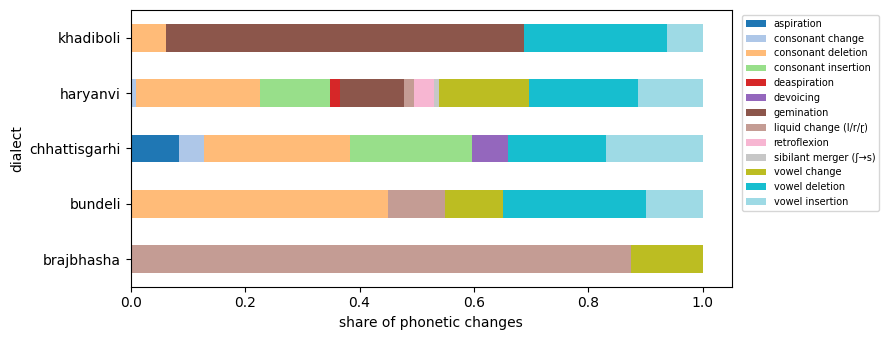

In [32]:
# @title 9a · Phonetic and lexical level
prof = pd.read_csv(DS / "features/phonetic_category_profile.csv", index_col=0)
display(prof)
display(pd.read_csv(DS / "features/lexical_substitutions_eval_sentences.csv")[["sentence_id", "target_dialect", "rendered", "lexical_substitutions", "rule_changes"]])
import matplotlib.pyplot as plt
share = prof.div(prof.sum(axis=1), axis=0)
ax = share.plot(kind="barh", stacked=True, figsize=(9, 3.5), colormap="tab20", legend=False)
ax.set_xlabel("share of phonetic changes"); ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()

In [33]:
# @title 9b · Prosodic level and dialect prosody profiles
from app.features.prosodic import prosodic_features, prosody_profiles
from app.utils.audio import read_wav

man_path = DS / "corpus/manifest.csv"            # your recorded corpus (copy of manifest_PLANNED.csv with recordings)
items = []
if man_path.exists():
    man = pd.read_csv(man_path)
    items = [(DS / r.audio_path, r.text, r.dialect, r.gender, "corpus") for r in man.itertuples() if (DS / r.audio_path).exists()]
elif any(NAT.glob("REF_*.wav")):
    for r in SENT_DF.itertuples():
        p = NAT / f"REF_{r.sentence_id:02d}.wav"
        if p.exists():
            items.append((p, r.text_hi, r.target_dialect, r.voice, "natural reference"))
if not items:
    print("No natural speech yet – upload corpus recordings or natural references. Profiles stay neutral.")
else:
    feats = pd.DataFrame([{"file": str(p), "dialect": d, "gender": g, "source": s, **prosodic_features(*read_wav(p), text)}
                          for p, text, d, g, s in items])
    feats.to_csv(WORK / "prosodic_features.csv", index=False)
    display(feats.groupby(["dialect", "gender"])[["f0_mean_hz", "f0_range_st", "articulation_rate_syl_s", "pause_ratio", "npvi_voiced"]].mean().round(2))
    if "khadiboli" in set(feats.dialect):
        prof_m = prosody_profiles(feats, "khadiboli")
        prof_m.to_csv(WORK / "prosody_profiles_measured.csv", index=False)
        display(prof_m)
        print("Saved – re-run section 7a to apply these profiles to M4/M5.")
    else:
        print("Need Khadi Boli recordings as reference to compute profiles.")

No natural speech yet – upload corpus recordings or natural references. Profiles stay neutral.


## 10 · Ratings and bias correction (MTP-1 §4.5:  y = a·x + b)
Upload the evaluators' filled sheets (`E01_MOS.csv`, `E01_DMOS.csv`, … or one zip), **or** tick
`USE_DEMO_RATINGS` to test with the simulated ratings in the dataset (planted bias – **never report these numbers**).

For each listener dialect d and test (MOS, DMOS) the toolkit estimates **y = a_d·x + b_d**, where x is the
score given by a listener of dialect d and y is the score a reference (Khadi Boli) listener would give.
`a` is estimated by mean–sigma equating (not biased towards 0); if its 95 % bootstrap CI contains 1 only the
offset b is corrected. The reference paper's OLS fit (`regression_ols`) and other methods are shown for comparison.

In [34]:
# @title 10a · Load ratings
USE_DEMO_RATINGS = True  # @param {type:"boolean"}
from app.data.design import collect_rating_sheets
SHEETS = WORK / "returned_sheets"; SHEETS.mkdir(exist_ok=True)
if USE_DEMO_RATINGS:
    RATINGS = pd.read_csv(DS / "ratings/ratings_SIMULATED_demo_DO_NOT_REPORT.csv")
    TAG = " [SIMULATED DEMO]"
else:
    try:
        from google.colab import files
        for name, data in files.upload().items():
            target = SHEETS / Path(name).name
            target.write_bytes(data)
            if name.endswith(".zip"):
                with zipfile.ZipFile(target) as z: z.extractall(SHEETS)
    except ImportError:
        pass
    for p in SHEETS.rglob("E*_*.csv"):          # flatten any folders from the zip
        if p.parent != SHEETS: shutil.copy(p, SHEETS / p.name)
    key = pd.read_csv(DS / "stimuli/playlists_KEY_researcher_only.csv")
    RATINGS = collect_rating_sheets(SHEETS, key, PANEL_DF)
    TAG = ""
assert len(RATINGS), "no ratings found"
RATINGS.to_csv(WORK / "ratings.csv", index=False)
print(len(RATINGS), "ratings from", RATINGS.evaluator_id.nunique(), "evaluators", TAG)
display(RATINGS.groupby(["test_type", "listener_dialect"]).size().unstack(0))

2000 ratings from 10 evaluators  [SIMULATED DEMO]


test_type,DMOS,MOS
listener_dialect,,
brajbhasha,200,200
bundeli,200,200
chhattisgarhi,200,200
haryanvi,200,200
khadiboli,200,200


In [35]:
# @title 10b · MOS / DMOS, bias correction and impact
from app.evaluation.mos import mos_table
from app.evaluation import bias as B
from app.evaluation.reliability import impact_metrics
from app.evaluation.stats import paired_comparison, holm
REF = "khadiboli"
first = RATINGS[~RATINGS["is_repeat"].astype(bool)] if "is_repeat" in RATINGS else RATINGS

print("Raw MOS/DMOS per model" + TAG)
display(mos_table(first, ("test_type", "model")).round(3))

reg = B.RegressionBiasCorrector(reference=REF, estimator="equating", n_boot=1000).fit(RATINGS)
COEF = reg.summary()
print("y = a·x + b per listener dialect" + TAG)
display(COEF[["test_type", "dialect", "a", "b", "a_ci_low", "a_ci_high", "a_ols", "b_ols", "a_used", "b_used", "method_used"]].round(3))

CORR, IMPACT = {}, []
for m in ["none", "regression_ols", "regression", "offset", "zscore", "mixed"]:
    c = B.get_corrector(m, REF, **({"n_boot": 500} if m == "regression" else {}))
    CORR[m] = c.fit_transform(RATINGS)
    for tt, g in CORR[m].groupby("test_type"):
        IMPACT.append({"method": m, "test_type": tt, **impact_metrics(g, "score_corrected", REF)})
IMPACT = pd.DataFrame(IMPACT)
print("Impact of the correction (gap between listener groups ↓, model range kept)" + TAG)
display(IMPACT[["method", "test_type", "between_group_gap", "eta_squared_dialect", "model_range", "icc_2_1", "krippendorff_alpha", "kendall_W_model_ranking"]].round(3))

cor = CORR["regression"]; cf = cor[~cor["is_repeat"].astype(bool)] if "is_repeat" in cor else cor
COMP = pd.concat([mos_table(cf, ("test_type", "model"), "score").assign(version="raw"),
                  mos_table(cf, ("test_type", "model"), "score_corrected").assign(version="corrected")])
rows = []
for tt, g in cf.groupby("test_type"):
    per = g.groupby(["evaluator_id", "model"])["score_corrected"].mean().unstack()
    for m in [c for c in per.columns if c != "M1"]:
        rows.append({"test_type": tt, "model": m, "vs": "M1", **paired_comparison(per["M1"], per[m])})
PAIRED = pd.DataFrame(rows)
if len(PAIRED):
    PAIRED["wilcoxon_p_holm"] = holm(PAIRED["wilcoxon_p"])
    print("Corrected scores: each model vs baseline M1" + TAG)
    display(PAIRED[["test_type", "model", "mean_diff", "ci_low", "ci_high", "cohens_dz", "wilcoxon_p", "wilcoxon_p_holm"]].round(4))

Raw MOS/DMOS per model [SIMULATED DEMO]


,test_type,model,n,mean,std,ci_low,ci_high
0,DMOS,M1,200,3.210,0.692,3.114,3.306
1,DMOS,M2,200,3.510,0.680,3.415,3.605
2,DMOS,M3,200,3.430,0.606,3.346,3.514
3,DMOS,M4,200,3.680,0.624,3.593,3.767
4,DMOS,M5,200,3.760,0.659,3.668,3.852
5,MOS,M1,200,3.570,0.622,3.483,3.657
6,MOS,M2,200,3.880,0.589,3.798,3.962
7,MOS,M3,200,3.805,0.640,3.716,3.894
8,MOS,M4,200,3.925,0.657,3.833,4.017
9,MOS,M5,200,4.070,0.684,3.975,4.165


y = a·x + b per listener dialect [SIMULATED DEMO]


,test_type,dialect,a,b,a_ci_low,a_ci_high,a_ols,b_ols,a_used,b_used,method_used
0,DMOS,brajbhasha,0.922,-0.081,0.746,1.133,0.285,2.234,1.0,-0.365,offset (a=1: CI of a contains 1)
1,DMOS,bundeli,0.900,0.481,0.765,1.065,0.280,2.402,1.0,0.170,offset (a=1: CI of a contains 1)
2,DMOS,chhattisgarhi,0.942,-0.094,0.794,1.101,0.200,2.555,1.0,-0.300,offset (a=1: CI of a contains 1)
3,DMOS,haryanvi,0.937,-0.493,0.733,1.179,0.101,2.864,1.0,-0.745,offset (a=1: CI of a contains 1)
4,MOS,brajbhasha,1.026,-0.586,0.907,1.158,0.208,2.705,1.0,-0.480,offset (a=1: CI of a contains 1)
5,MOS,bundeli,0.839,0.633,0.695,1.001,0.097,3.204,1.0,0.075,offset (a=1: CI of a contains 1)
6,MOS,chhattisgarhi,0.891,0.049,0.782,1.013,0.175,2.855,1.0,-0.380,offset (a=1: CI of a contains 1)
7,MOS,haryanvi,1.027,-0.880,0.870,1.248,0.169,2.812,1.0,-0.765,offset (a=1: CI of a contains 1)


Impact of the correction (gap between listener groups ↓, model range kept) [SIMULATED DEMO]


,method,test_type,between_group_gap,eta_squared_dialect,model_range,icc_2_1,krippendorff_alpha,kendall_W_model_ranking
0,none,DMOS,0.915,0.921,0.550,0.109,0.085,0.920
1,none,MOS,0.840,0.941,0.500,0.082,0.058,0.802
2,regression_ols,DMOS,0.000,0.000,0.195,0.074,0.068,0.920
3,regression_ols,MOS,0.000,0.000,0.135,0.053,0.053,0.802
4,regression,DMOS,0.002,0.000,0.549,0.142,0.140,0.920
5,regression,MOS,0.002,0.000,0.499,0.108,0.106,0.802
6,offset,DMOS,0.002,0.000,0.549,0.142,0.140,0.920
7,offset,MOS,0.002,0.000,0.499,0.108,0.106,0.802
8,zscore,DMOS,0.001,0.771,0.548,0.147,0.146,0.920
9,zscore,MOS,0.000,0.000,0.472,0.111,0.111,0.752


Corrected scores: each model vs baseline M1 [SIMULATED DEMO]


,test_type,model,mean_diff,ci_low,ci_high,cohens_dz,wilcoxon_p,wilcoxon_p_holm
0,DMOS,M2,0.3000,0.2046,0.3954,2.2500,0.0020,0.0156
1,DMOS,M3,0.2192,0.1183,0.3200,1.5546,0.0039,0.0156
2,DMOS,M4,0.4700,0.3924,0.5476,4.3308,0.0020,0.0156
3,DMOS,M5,0.5491,0.4439,0.6544,3.7311,0.0020,0.0156
4,MOS,M2,0.3096,0.1933,0.4259,1.9042,0.0020,0.0156
5,MOS,M3,0.2342,0.1081,0.3604,1.3289,0.0078,0.0156
6,MOS,M4,0.3546,0.2683,0.4410,2.9374,0.0020,0.0156
7,MOS,M5,0.4992,0.3664,0.6321,2.6883,0.0020,0.0156


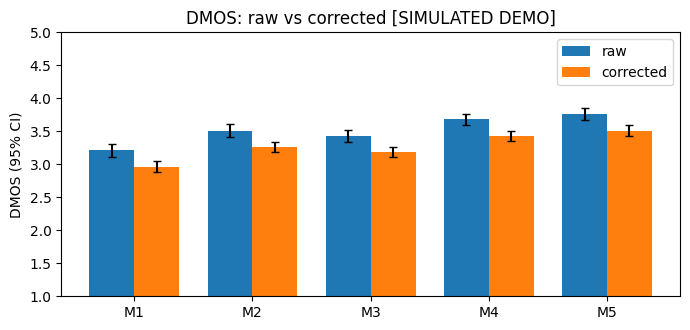

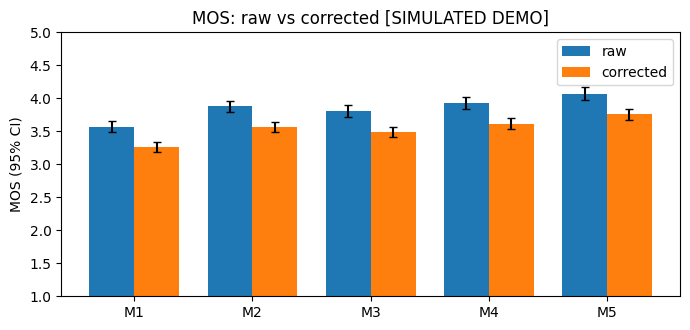

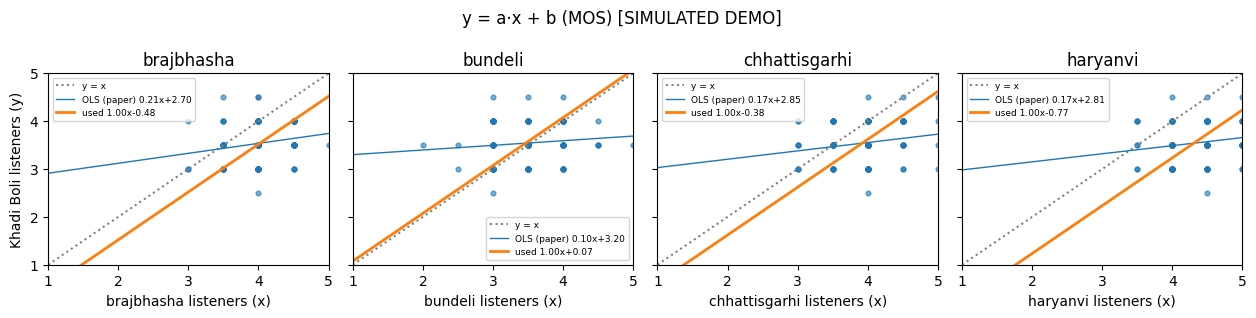

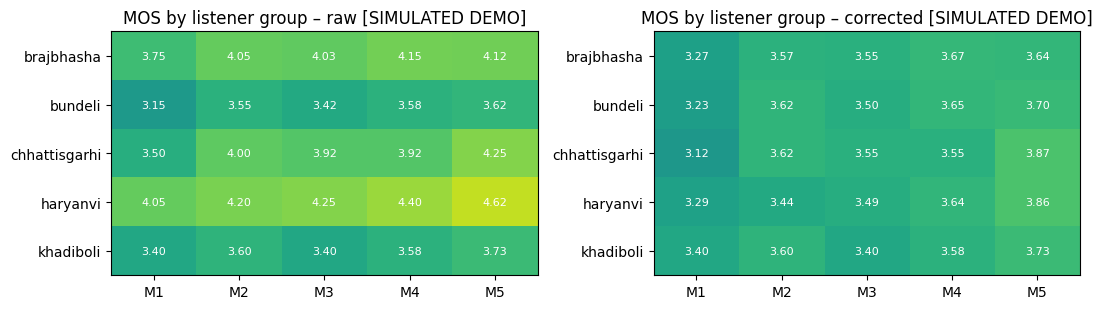

results: /content/mtp_work/MTP_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
# @title 10c · Graphs and download of all results
import matplotlib.pyplot as plt, numpy as np
FIG = WORK / "figures"; FIG.mkdir(exist_ok=True)
for tt in COMP.test_type.unique():
    t = COMP[COMP.test_type == tt]; models = sorted(t.model.unique()); x = np.arange(len(models))
    fig, ax = plt.subplots(figsize=(7, 3.4))
    for i, v in enumerate(["raw", "corrected"]):
        s = t[t.version == v].set_index("model").reindex(models)
        ax.bar(x + (i - 0.5) * 0.38, s["mean"], 0.38, yerr=[s["mean"] - s.ci_low, s.ci_high - s["mean"]], capsize=3, label=v)
    ax.set_xticks(x, models); ax.set_ylim(1, 5); ax.set_ylabel(f"{tt} (95% CI)"); ax.legend(); ax.set_title(f"{tt}: raw vs corrected{TAG}")
    plt.tight_layout(); fig.savefig(FIG / f"{tt}_by_model.png", dpi=200); plt.show()

mos = RATINGS[RATINGS.test_type == "MOS"]
wide = B.item_means(mos); fits = COEF[COEF.test_type == "MOS"]
fig, axes = plt.subplots(1, len(fits), figsize=(3.2 * len(fits), 3.2), sharey=True, squeeze=False)
for ax, f in zip(axes[0], fits.itertuples()):
    pair = wide[[f.dialect, REF]].dropna(); xs = np.linspace(1, 5, 20)
    ax.scatter(pair[f.dialect], pair[REF], s=12, alpha=.6)
    ax.plot(xs, xs, ":", color="grey", label="y = x")
    ax.plot(xs, f.a_ols * xs + f.b_ols, lw=1, label=f"OLS (paper) {f.a_ols:.2f}x{f.b_ols:+.2f}")
    ax.plot(xs, f.a_used * xs + f.b_used, lw=2, label=f"used {f.a_used:.2f}x{f.b_used:+.2f}")
    ax.set_title(f.dialect); ax.set_xlim(1, 5); ax.set_ylim(1, 5); ax.set_xlabel(f"{f.dialect} listeners (x)"); ax.legend(fontsize=6.5)
axes[0][0].set_ylabel("Khadi Boli listeners (y)"); fig.suptitle("y = a·x + b (MOS)" + TAG); plt.tight_layout()
fig.savefig(FIG / "regression_per_dialect.png", dpi=200); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, col, title in [(axes[0], "score", "raw"), (axes[1], "score_corrected", "corrected")]:
    m = CORR["regression"][CORR["regression"].test_type == "MOS"].groupby(["listener_dialect", "model"])[col].mean().unstack()
    im = ax.imshow(m.values, vmin=1, vmax=5, cmap="viridis", aspect="auto")
    ax.set_xticks(range(m.shape[1]), m.columns); ax.set_yticks(range(m.shape[0]), m.index); ax.set_title(f"MOS by listener group – {title}{TAG}")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]): ax.text(j, i, f"{m.iat[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
plt.tight_layout(); fig.savefig(FIG / "heatmaps.png", dpi=200); plt.show()

# objective: MCD against natural references (if uploaded)
if "MANIFEST" in globals() and any(NAT.glob("REF_*.wav")):
    from app.evaluation.objective import objective_table
    OBJ = objective_table(MANIFEST, NAT)
    OBJ.to_csv(WORK / "objective_metrics.csv", index=False)
    display(OBJ.groupby("model")["mcd_db"].mean().round(2).to_frame("MCD (dB)"))

for name, df in {"mos_raw_vs_corrected": COMP, "regression_coefficients": COEF, "bias_impact": IMPACT,
                 "paired_vs_M1": PAIRED, "ratings_corrected": CORR["regression"]}.items():
    df.to_csv(WORK / f"{name}.csv", index=False)
RES = WORK / "results"
if RES.exists(): shutil.rmtree(RES)
RES.mkdir()
for f in list(WORK.glob("*.csv")): shutil.copy(f, RES / f.name)
shutil.copytree(FIG, RES / "figures")
res_zip = shutil.make_archive(str(WORK / "MTP_results"), "zip", RES)
print("results:", res_zip)
try:
    from google.colab import files; files.download(res_zip)
except ImportError:
    pass

## Troubleshooting

* **`numpy` / "restart session" message after installing** – click *Restart session*, then *Run all* again (the downloads are kept).
* **`WeightsUnpickler error` / `weights_only`** – cell 4b already patches `torch.load`; make sure you ran 4b after a restart.
* **`KeyError: 'female'` speaker** – the speaker file path wasn't fixed; rerun 4a.
* **Indic Parler-TTS 401/403** – open the model page on Hugging Face, accept the terms, then `notebook_login()`.
* **Out of memory (Parler)** – use a GPU runtime, or switch to `indic_tts`.
* `mode="char"` with `LEVEL="full"` applies every pattern from the paper and can over-apply; `combined` + `conservative` is the safest default.
* Dictionary rows marked `community_seed` are unverified; check them with native speakers.
* **Section 7a says “engines available: []”** – run 4a/4b (Indic-TTS) and, for M2/M5, set `USE_PARLER = True` and run 4c.
* **`AssertionError: Load the dataset first`** – run 2b and upload `MTP_Hindi_Dialect_Dataset.zip`.
* **`ValueError: … need ≥5 stimuli rated by both groups`** – some evaluator sheets are missing; every listener group, including Khadi Boli, must return both sheets.
* **Results marked [SIMULATED DEMO]** – set `USE_DEMO_RATINGS = False` and upload the real sheets.